# Phase 2: Multi-Task Spatio-Temporal Forecasting Engine
**Objective:** Develop and evaluate a GRU-based Multi-Task Learning (GRU-MTL) model against statistical, machine-learning, single-task and spatial baselines for one-quarter-ahead prediction of sub-county capacity-stress states and traffic-load gaps.

**In plain words.** Notebook 03 produced a panel with one row per sub-county per quarter. This notebook uses it to answer two questions about every sub-county, one quarter ahead:
1. **Will it be stressed next quarter?** Stressed means its load-to-capacity ratio is in the top 20% of that quarter. The answer is yes or no, so this is a **classification** task.
2. **How large will its load gap be?** The gap is the estimated traffic above the quarter's stress threshold, in TB. It is a number, so this is a **regression** task. The gap is zero whenever the sub-county is not stressed.

**Multi-task learning (MTL)** means training one model to solve several related tasks at the same time. In the GRU-MTL model both tasks share one sequence encoder (the part of the network that reads the last four quarters of data), and each task has its own small output layer, called a *head*. The idea is that the patterns that help predict *whether* stress occurs should also help predict *how large* it is, so learning them together can make better use of a small data set. Whether this actually helps is what hypothesis H1 tests.

| | |
|---|---|
| **Pipeline** | 01 Spatial canvas → 02 Temporal extraction → 03 Spatial downscale → **04 MTL engine** → 05 Explainability & NDS |
| **Answers** | Research Question 3 and Specific Objective 2; hypotheses H1–H3 |
| **Input** | `Data/processed/subcounty_panel.parquet` from Notebook 03 (294 sub-counties × 17 quarters) |
| **Outputs** | `Outputs/models/` (final GRU-MTL seeds, XGBoost pair, scalers, next-quarter forecast); Tables 4.9–4.22; Figures 4.6–4.8 |

**Structure of this notebook:**
1. Pre-estimation tests: descriptive statistics, stationarity, multicollinearity, spatial autocorrelation, class balance and zero-inflation
2. Feature construction: sliding windows of $L = 4$ quarters, spatial-lag features from the 5 nearest sub-counties
3. Temporal driver: ARIMA and ETS forecasts of the national CA series
4. Baselines: persistence, seasonal-naive, logistic regression + two-part (hurdle) regression, XGBoost, LightGBM
5. Neural models: GRU-MTL (proposed), single-task GRUs, LSTM-MTL, GRU-MTL without spatial lags, T-GCN (graph convolution + GRU)
6. Hyperparameter selection by expanding-window rolling-origin validation, 5 random seeds per neural model
7. Hypothesis tests: DeLong and sub-county cluster bootstrap (AUC), Diebold–Mariano (gap errors), residual Moran's I
8. Performance by infrastructure-density stratum and spatial generalisation by county holdout
9. Uncertainty: split-conformal prediction intervals for the load gap; probability calibration
10. Refit on all quarters and forecast the next quarter (Q4 2025/26) for the NDS in Notebook 05

**Where to find each part.** Steps 1–3 load the panel, run the pre-estimation tests and build the samples. Step 4 fits the national ARIMA/ETS benchmarks. Step 5 defines how every model is scored. Steps 6 and 7 fit the naive, statistical and tree-based baselines. Step 8 defines, tunes and trains the neural models. Step 9 gives the main results table, Step 10 the hypothesis tests, Step 11 the strata and county holdout, Step 12 the uncertainty analysis and Step 13 the final refit and forecast.

**Research hypotheses tested here** (formalised from Research Question 3 for this study; the approved proposal states research questions, not hypotheses):
- **H1:** The GRU-MTL model achieves higher discrimination (ROC-AUC, PR-AUC) than single-task GRU and XGBoost baselines.
- **H2:** Adding spatial information (spatial-lag features or graph convolution) improves forecasting accuracy.
- **H3:** After modelling, forecast residuals show no significant spatial autocorrelation.

**Terms used throughout the notebook:**
- **Sub-county-quarter:** one row of the panel, that is, one sub-county in one quarter.
- **`q_idx`:** the quarter number, from 0 (Q3 2021/22) to 16 (Q3 2025/26). Quarter labels follow the CA's financial-year naming.
- **Development period and test period:** models are built and tuned using only target quarters up to 12 (Q3 2024/25). The last four quarters (13–16) are kept aside as a test set that no model sees during fitting or tuning, so the reported scores show how the models do on quarters they have never seen.
- **Data leakage:** using information from the test period (or from the future) while building a model, which makes test scores look better than they would be in real use. The code below avoids it at every step, for example by fitting scalers on development rows only.

In [1]:
# ---- Imports and settings ------------------------------------------------------------
# `from project_config import *` loads everything defined in project_config.py: numpy (np),
# pandas (pd), matplotlib (plt), the folder paths, the study constants (TRAIN_MAX_Q, L,
# K_NEIGH, SEEDS, FOLDS, XGB_FIXED), the helpers save_table, save_figure and morans_i,
# and the neural network classes SeqNet and TGCN.
from project_config import *
# Standard-library helpers: json and pickle save files at the end, time measures run times,
# and inspect/textwrap print the source code of the network classes in Step 8.
import json, pickle, time, inspect, textwrap
# PyTorch is the deep-learning library used for the GRU, LSTM and T-GCN models.
# torch.nn ("neural network") holds the building blocks: layers and loss functions.
import torch
import torch.nn as nn
from scipy import stats                                  # probability distributions (p-values)
from sklearn.neighbors import BallTree                   # fast nearest-neighbour search
from sklearn.preprocessing import StandardScaler         # rescales columns to mean 0, sd 1
from sklearn.linear_model import LogisticRegression      # the logit baseline (Step 6)
# Scoring functions for the stress task; each metric is explained in Step 5.
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, balanced_accuracy_score, brier_score_loss)
import statsmodels.api as sm                             # OLS regression and add_constant
from statsmodels.tsa.stattools import adfuller, kpss     # stationarity tests (Step 2.2)
from statsmodels.stats.outliers_influence import variance_inflation_factor   # VIF (Step 3.1)
from statsmodels.tsa.holtwinters import ExponentialSmoothing   # ETS model (Step 4)
from statsmodels.tsa.arima.model import ARIMA            # ARIMA model (Step 4)
import xgboost as xgb                                    # gradient-boosted trees (Step 7)
import lightgbm as lgb                                   # a second boosting library (Step 7)
import warnings
# Hide library warnings (for example the note statsmodels gives when a KPSS p-value lies
# outside its look-up table) so the printed output stays readable.
warnings.filterwarnings('ignore')

torch.set_num_threads(4)   # let PyTorch use at most 4 CPU threads (no GPU is needed)
# TRAIN_MAX_Q, L, K_NEIGH, SEEDS and FOLDS come from project_config.py
# Print the key design settings so they are recorded in the notebook output:
#   TRAIN_MAX_Q = last target quarter of the development period, L = window length in
#   quarters, K_NEIGH = neighbours per sub-county, SEEDS = random seeds for the networks,
#   FOLDS = (train up to this quarter, validation quarters) pairs for rolling-origin tuning.
print(f"Development targets up to q_idx {TRAIN_MAX_Q} | lookback L = {L} | {K_NEIGH} spatial neighbours | seeds {SEEDS} | folds {FOLDS}")
# Library versions are printed because other versions can change results slightly.
print(f"PyTorch {torch.__version__} | XGBoost {xgb.__version__} | LightGBM {lgb.__version__}")

Development targets up to q_idx 12 | lookback L = 4 | 5 spatial neighbours | seeds [0, 1, 2, 3, 4] | folds [(8, (9, 10)), (10, (11, 12))]
PyTorch 2.14.1+cu130 | XGBoost 3.4.1 | LightGBM 4.7.0


## Step 1: Panel Ingestion and Derived Variables
**What this step does.** It loads the sub-county × quarter panel saved by Notebook 03, checks that every sub-county has all 17 quarters, and creates the extra variables (features) that the models use as inputs. It also builds the spatial weights that say which sub-counties are neighbours.

**Why the study needs it.** The raw panel columns are on very different scales (GB of traffic, counts of cells, Mbps) and several are strongly skewed, with a few very large sub-counties. Ratios and log transforms turn them into features a model can learn from, and the spatial-lag features let a model see what is happening in nearby sub-counties.

**Derived variables** (the names are the column names created in the code):
- `rel_ratio` $= \ln\left(1 + r_{s,t}/\tau_t\right)$ places each sub-county relative to the quarter's stress threshold (values above $\ln 2 \approx 0.69$ mean stressed). Here $r_{s,t}$ is the load-to-capacity ratio of sub-county $s$ in quarter $t$ and $\tau_t$ is that quarter's stress threshold from Notebook 03, so $r_{s,t}/\tau_t > 1$ exactly when the sub-county is stressed.
- `log_gap` $= \ln(1 + \text{gap}_{s,t})$ is the current load gap, so the regression head sees the present magnitude.
- `dev_share_pct` is the sub-county's share of all Ookla devices in Kenya in that quarter, in percent (a demand indicator). `log_tests` is $\ln(1 + \text{number of Ookla tests})$.
- Ookla download speed is filled with the quarter median where a sub-county had no tests (`dl_mbps_f`); `low_confidence` flags those cases. (`low_confidence` = 1 when a sub-county-quarter had fewer than 20 Ookla tests, which includes every case with no tests.)
- `nat_growth` is the quarter-on-quarter growth of the national data volume, measured as the difference in logs (roughly the percentage growth). It is the same for every sub-county in a quarter and is set to 0 for the first quarter.
- Infrastructure features from the cell registry: `log_capacity` (log of the weighted capacity proxy from Notebook 03), `lte_share` and `umts_share` (shares of 4G and 3G cells among all cells) and `log_sites` (log of the number of approximate sites). These do not change over time.
- The load gap is expressed in **TB** (1 TB = 1,000 GB) for readability. Like the load, it is a **downscaled estimate** (allocated national volume above the quarter's stress threshold), not measured traffic.

Why $\ln(1 + x)$ rather than $\ln(x)$: some values (Ookla tests, load gaps) are exactly 0, and $\ln(0)$ is undefined, while $\ln(1 + 0) = 0$. The transform still compresses large values, which reduces skewness.

**Spatial weights and spatial lags.**
- For each sub-county the code finds its 5 nearest sub-counties, using the great-circle distance between their centre points (the mean location of their sites).
- These form a 294 × 294 weight matrix `W_knn` with $w_{ij} = 1/5$ when $j$ is one of $i$'s 5 nearest neighbours and 0 otherwise. Each row sums to 1 (**row-standardised**), so multiplying the matrix by a variable gives the average of the neighbours' values.
- The **spatial lag** of a variable $x$ is $\sum_j w_{ij}\, x_{j,t}$, the average value of the 5 neighbours in the same quarter. Two are created: `splag_rel_ratio` (how stressed the neighbours are) and `splag_dev_share_pct` (how much demand the neighbours have).

**How to read the output.** One line confirms the panel size: 294 sub-counties × 17 quarters. If any sub-county were missing a quarter, the `assert` check in the code would stop the notebook with an error instead.

In [2]:
# ---- 1a. Load the panel ----------------------------------------------------------------
# Read the panel from Notebook 03 and sort it by sub-county, then by quarter, so the rows run:
# sub-county A quarters 0..16, sub-county B quarters 0..16, and so on.
# reset_index(drop=True) renumbers the rows 0, 1, 2, ... after sorting.
panel = pd.read_parquet(PROCESSED + 'subcounty_panel.parquet').sort_values(['subcounty', 'q_idx']).reset_index(drop=True)
units = np.sort(panel['subcounty'].unique())    # the 294 sub-county names, in sorted order
N, T = len(units), panel['q_idx'].nunique()     # N = number of sub-counties, T = quarters
# Safety check: the sorted panel must be "each sub-county repeated T times" in the same order
# as `units` (np.repeat(units, T) builds that expected order). If a sub-county had a missing
# quarter, the comparison would fail and `assert` would stop the notebook with an error.
assert (panel['subcounty'].values == np.repeat(units, T)).all()

# ---- 1b. Derived variables ---------------------------------------------------------------
# Relative stress ratio: load/capacity divided by the quarter's threshold tau_t, then
# log(1 + x). np.log1p(x) computes ln(1 + x) and keeps 0 at 0.
panel['rel_ratio'] = np.log1p(panel['load_capacity_ratio'] / panel['tau_t'])
panel['dev_share_pct'] = 100 * panel['dev_share']      # share of national Ookla devices, in %
panel['log_tests'] = np.log1p(panel['tests'])          # log(1 + Ookla tests), a skewed count
# Fill missing download speeds with that quarter's median speed across all sub-counties.
# groupby('q_idx')[...].transform('median') gives every row the median of its own quarter,
# so the result lines up row by row with `panel` and can be passed to fillna().
panel['dl_mbps_f'] = panel['dl_mbps'].fillna(panel.groupby('q_idx')['dl_mbps'].transform('median'))
# National volume per quarter: the sum of the downscaled load over all sub-counties.
national = panel.groupby('q_idx')['load_GB'].sum()   # equals the CA national total (mass-preserving downscaling)
# National growth: log(volume this quarter) - log(volume last quarter). diff() leaves the
# first quarter empty (NaN), so fillna(0) sets it to 0. .map() then copies each quarter's
# growth onto every sub-county row of that quarter.
panel['nat_growth'] = panel['q_idx'].map(np.log(national).diff().fillna(0))
cells_total = panel['n_GSM'] + panel['n_UMTS'] + panel['n_LTE']   # all 2G + 3G + 4G cells
panel['log_capacity'] = np.log1p(panel['capacity_units'])   # log of the capacity proxy
panel['lte_share'] = panel['n_LTE'] / cells_total           # share of cells that are 4G (LTE)
panel['umts_share'] = panel['n_UMTS'] / cells_total         # share of cells that are 3G (UMTS)
panel['log_sites'] = np.log1p(panel['n_sites'])             # log(1 + number of sites)
panel['gap_TB'] = panel['traffic_deficit_GB'] / 1000        # load gap converted from GB to TB
panel['log_gap'] = np.log1p(panel['gap_TB'])                # current gap on the log scale

# ---- 1c. Spatial weights and spatial lags ------------------------------------------------
# Spatial weights: 5 nearest sub-counties by centroid distance (row-standardised)
# One centre point per sub-county (lat/lon are the same in every quarter, so .first() just
# takes it), with the rows put in the same order as `units` by .loc[units].
cent = panel.groupby('subcounty')[['lat', 'lon']].first().loc[units]
# BallTree finds nearest neighbours quickly. metric='haversine' measures great-circle
# distance on a sphere and needs coordinates in radians (np.radians). K_NEIGH + 1 neighbours
# are requested because the closest point to each sub-county is the sub-county itself.
# .query() returns (distances, indices); the distances are not needed, so they go to `_`.
_, nn_idx = BallTree(np.radians(cent.values), metric='haversine').query(np.radians(cent.values), k=K_NEIGH + 1)
nn_idx = nn_idx[:, 1:]   # drop column 0 (the sub-county itself): shape (N, 5)
# Build the N x N weight matrix: row i gets 1/5 in the columns of its 5 neighbours and 0
# elsewhere, so every row sums to 1. The two index arrays pair up as (row 0, its 1st
# neighbour), (row 0, its 2nd neighbour), ...: np.repeat gives the row numbers 0,0,0,0,0,1,...
# and nn_idx.ravel() flattens the neighbour numbers into one list in the same order.
W_knn = np.zeros((N, N))
W_knn[np.repeat(np.arange(N), K_NEIGH), nn_idx.ravel()] = 1.0 / K_NEIGH

# Helper used throughout the notebook: reshape one column from "long" format (one row per
# sub-county-quarter) to a "wide" N x T numpy array (rows = sub-counties, columns = quarters).
def wide(col):
    """(N sub-counties x T quarters) array of a panel column."""
    return panel.pivot(index='subcounty', columns='q_idx', values=col).loc[units].values

# Spatial lag = average of the 5 neighbours' values in the same quarter. `@` is matrix
# multiplication: (N x N) @ (N x T) gives an N x T array. .ravel() flattens it row by row
# (sub-county A's 17 quarters, then B's, ...), which matches the panel's sort order.
for v in ['rel_ratio', 'dev_share_pct']:
    panel['splag_' + v] = (W_knn @ wide(v)).ravel()

print(f"{N} sub-counties x {T} quarters = {len(panel):,} sub-county-quarters")

294 sub-counties x 17 quarters = 4,998 sub-county-quarters


## Step 2: Pre-Estimation Tests
Before any model is fitted, Step 2 describes the data and checks the statistical properties that affect which models make sense: what the variables look like, whether the national series is stationary, whether neighbouring sub-counties resemble each other, and how unbalanced the targets are.

### 2.1 Descriptive statistics, missingness, class balance and zero-inflation
**What it does.** Table 4.9 gives the count, mean, standard deviation, minimum, median (`50%`) and maximum of the main panel variables, plus the percentage of missing values (`missing_%`). Four printed lines then report:
- the **stress rate**, the share of sub-county-quarters labelled stressed. Stress is defined as the top 20% of each quarter, so this is close to 20% by construction. This is the **class balance**: roughly one stressed case for every four unstressed ones. Plain accuracy would be misleading here, because a model that always says "not stressed" would already be right about 80% of the time; that is why Step 5 uses ROC-AUC, PR-AUC and balanced accuracy instead.
- the **zero-gap share**, the share of sub-county-quarters whose load gap is exactly 0. The gap is positive only for stressed sub-county-quarters, so most values are zero. Data with many exact zeros plus a skewed positive part are called **zero-inflated**. This is why the gap is modelled in two parts (a **hurdle** structure): first "is there a gap at all?", then "how large is it, given that there is one?".
- the share of sub-county-quarters with fewer than 20 Ookla tests (low confidence in the demand measure);
- the CA quarters whose national data volume was imputed in Notebook 02.

**How to read Table 4.9.** Compare the mean with the median: when the mean is far above the median, the variable is right-skewed (a few very large values), which is why logs are used for the features. `missing_%` shows which variables have gaps; download speed and latency are missing where a sub-county-quarter had no Ookla tests.

In [3]:
# The raw variables to summarise (units: GB, capacity units, counts, Mbps, ms, TB).
desc_cols = ['load_GB', 'capacity_units', 'load_capacity_ratio', 'tests', 'devices', 'dl_mbps',
             'latency_ms', 'n_sites', 'lte_share', 'gap_TB']
# .describe() computes count, mean, std, min, percentiles and max for each column;
# percentiles=[0.5] asks only for the median ('50%'). .T transposes the result so each
# variable is a row, and [[...]] keeps the listed statistics in this order.
desc = panel[desc_cols].describe(percentiles=[0.5]).T[['count', 'mean', 'std', 'min', '50%', 'max']]
# .isna() is True where a value is missing. The mean of True/False values is the share that
# is True (True counts as 1), so 100 * mean = percentage missing.
desc['missing_%'] = 100 * panel[desc_cols].isna().mean()
desc.index.name = 'Variable'
print("Table 4.9: Descriptive statistics of the sub-county-quarter panel")
# save_table (project_config.py) writes Outputs/tables/T4.09_descriptives.csv and returns
# the table, so display() can show it in the notebook at the same time.
display(save_table(desc.round(3), '4.09', 'descriptives', index=True))

# The mean of a 0/1 column is the share of 1s, i.e. the share of stressed sub-county-quarters.
print(f"Stress rate: {panel['capacity_breach_target'].mean():.1%} (top 20% of each quarter, by construction)")
# (gap == 0) gives True/False for every row; its mean is the share of rows with no gap.
print(f"Zero-gap share: {(panel['traffic_deficit_GB'] == 0).mean():.1%} (hurdle structure)")
print(f"Sub-county-quarters with < 20 Ookla tests: {panel['low_confidence'].mean():.1%}")
# Boolean mask: keep rows with imputed_quarter == 1, take their Quarter labels, list each once.
print(f"Imputed CA quarters: {panel.loc[panel.imputed_quarter == 1, 'Quarter'].unique().tolist()}")

Table 4.9: Descriptive statistics of the sub-county-quarter panel
[saved] Outputs/tables/T4.09_descriptives.csv


,count,mean,std,min,50%,max,missing_%
Variable,,,,,,,
load_GB,4998.0,1603227.575,3471016.561,0.000,429090.041,3.920560e+07,0.000
capacity_units,4998.0,205.534,579.999,0.100,42.100,5.679300e+03,0.000
load_capacity_ratio,4998.0,21167.830,60528.125,0.000,9402.573,1.158491e+06,0.000
tests,4998.0,56.639,121.034,0.000,14.000,1.418000e+03,0.000
devices,4998.0,26.894,54.745,0.000,8.000,5.270000e+02,0.000
dl_mbps,4441.0,33.857,25.807,0.002,27.730,3.303040e+02,11.144
latency_ms,4441.0,60.571,60.679,0.000,40.556,2.211000e+03,11.144
n_sites,4998.0,138.517,207.538,1.000,69.500,1.829000e+03,0.000
lte_share,4998.0,0.011,0.016,0.000,0.000,6.900000e-02,0.000


Stress rate: 20.1% (top 20% of each quarter, by construction)
Zero-gap share: 79.9% (hurdle structure)
Sub-county-quarters with < 20 Ookla tests: 57.2%
Imputed CA quarters: ['Q2_22_23', 'Q3_22_23', 'Q4_22_23']


### 2.2 Stationarity of the national CA data series (ADF and KPSS)
**What stationarity means.** A time series is (weakly) stationary when its mean, variance and autocorrelation stay the same over time. A series with a steady upward trend, like national data volume, is not stationary in its levels. Many time-series models, ARIMA in particular, assume a stationary series, which is usually obtained by **differencing** (taking the change from one quarter to the next). The first difference of the log series is the quarter-on-quarter growth rate.

**The two tests.** They have opposite null hypotheses, so they are read together:
- **ADF (Augmented Dickey–Fuller):** $H_0$ = unit root (non-stationary). A small p-value (for example below 0.05) is evidence *for* stationarity.
- **KPSS (Kwiatkowski–Phillips–Schmidt–Shin):** $H_0$ = stationary. A small p-value is evidence *against* stationarity.

A series is clearly stationary when ADF rejects and KPSS does not, and clearly non-stationary when KPSS rejects and ADF does not; other combinations are inconclusive. With only 17 observations both tests have low power, so the results are indicative. KPSS p-values are bounded by the statsmodels look-up table (0.01–0.10), so values at the ends are shown as '<0.01' or '>0.10'.

**How the code does it.** `logY` is the log of the national series `national` from Step 1. Both tests are run on `logY` and on its first difference `np.diff(logY)`. The number of lags is fixed at one (`maxlag=1`, `nlags=1`) because the series is so short, and `regression='c'` makes KPSS test stationarity around a constant level.

**Why it matters here.** The national series is the common temporal driver of every sub-county's load. A trending, non-stationary level is the usual reason for working with growth rates instead of levels. In this notebook the models use national growth (`nat_growth`, the differenced log series) as a feature rather than the raw national volume, and the ARIMA model in Step 4 works on the once-differenced series (the middle 1 in ARIMA(1,1,0)).

**How to read Table 4.10.** One row per series (log level, first difference), with the ADF statistic and p-value and the KPSS statistic and p-value. Apply the reading rules above to each row.

In [4]:
logY = np.log(national.values)   # log national data volume, one value per quarter (17 values)
rows = []                        # one dictionary per tested series, turned into a table below
# Test two versions of the series: the log level, and its first difference (np.diff takes
# x[t] - x[t-1], i.e. quarterly log growth, so it has one value fewer).
for name, series in [('log national data volume', logY), ('first difference (quarterly growth)', np.diff(logY))]:
    # adfuller returns several values; [:2] keeps the test statistic and the p-value.
    # maxlag=1 with autolag=None uses exactly one lagged difference (the series is short).
    adf_stat, adf_p = adfuller(series, maxlag=1, autolag=None)[:2]
    # kpss: regression='c' tests stationarity around a constant level; nlags=1 sets the lags
    # used to estimate the long-run variance. [:2] again keeps the statistic and the p-value.
    kpss_stat, kpss_p = kpss(series, regression='c', nlags=1)[:2]
    rows.append({'Series': name, 'ADF stat': adf_stat, 'ADF p': adf_p, 'KPSS stat': kpss_stat, 'KPSS p': kpss_p})
stationarity = pd.DataFrame(rows).round(3)   # list of dictionaries -> table, 3 decimals
# Show KPSS p-values at the edges of the look-up table as '<0.01' or '>0.10'. A lambda is a
# small unnamed function; .map() applies it to every value of the column.
stationarity['KPSS p'] = stationarity['KPSS p'].map(lambda p: '<0.01' if p <= 0.01 else ('>0.10' if p >= 0.10 else f'{p:.3f}'))
print("Table 4.10: Stationarity tests of the national CA series")
display(save_table(stationarity, '4.10', 'stationarity'))

Table 4.10: Stationarity tests of the national CA series
[saved] Outputs/tables/T4.10_stationarity.csv


,Series,ADF stat,ADF p,KPSS stat,KPSS p
0,log national data volume,0.489,0.985,0.926,<0.01
1,first difference (quarterly growth),-2.780,0.061,0.117,>0.10


### 2.3 Spatial autocorrelation of the stress ratio (global Moran's I)
**What Moran's I measures.** Global Moran's I is the spatial counterpart of a correlation coefficient: it asks whether a sub-county's value tends to resemble the values of its neighbours.
$$I = \frac{N}{\sum_{i,j} w_{ij}} \cdot \frac{\sum_{i,j} w_{ij}\, z_i z_j}{\sum_i z_i^2}, \qquad z_i = x_i - \bar x$$
A positive $I$ means similar values cluster together (high next to high, low next to low). An $I$ near zero means no spatial pattern (its expected value under no spatial pattern is $-1/(N-1)$, very close to 0). A negative $I$ means neighbours tend to be dissimilar.

**How significance is tested.** `morans_i` (in `project_config.py`) uses a **permutation test**: it shuffles the values randomly across the sub-counties 999 times and recomputes $I$ each time, which shows what $I$ looks like when location does not matter. The p-value is two-sided: the share of shuffled results that lie at least as far from their average as the observed $I$ does. One is added to the count and to the 999, so the p-value is never exactly 0 and the smallest possible value is 0.001. This test does not need a normality assumption.

**What the code does.** It takes `rel_ratio` as an N × T array and computes Moran's I with the 5-nearest-neighbour weights `W_knn` for quarters 0, 4, 8, 12 and 16. These are the same quarter (Q3) of each financial year, so seasonal differences do not affect the comparison across years.

**Why it matters.** Significant positive Moran's I justifies spatial-lag features and the graph model (Tobler's First Law: near things are more related than distant things). The same statistic is used again on the model residuals in Step 10 to test H3.

**How to read Table 4.11.** One row per selected quarter. A positive `Moran's I` with `p (perm.)` below 0.05 indicates significant clustering of high (and of low) stress ratios in that quarter. Comparing the rows shows whether the clustering grows or weakens over time.

In [5]:
# morans_i(x, W) is defined in project_config.py (permutation test, 999 permutations)
RR = wide('rel_ratio')   # N x T array: rows = sub-counties, columns = quarters
# One table row per selected quarter q. RR[:, q] is column q, the stress ratio of all 294
# sub-counties in that quarter. morans_i returns the pair (I, p), and the * unpacks it into
# the list, giving [q, quarter label, I, p]. zip() pairs these four values with the four
# column names, and dict() turns the pairs into one row.
moran_rows = [dict(zip(['q_idx', 'Quarter', "Moran's I", 'p (perm.)'],
                       [q, panel.loc[panel.q_idx == q, 'Quarter'].iloc[0], *morans_i(RR[:, q], W_knn)]))
              for q in [0, 4, 8, 12, 16]]
moran_pre = pd.DataFrame(moran_rows).round(4)
print("Table 4.11: Global Moran's I of the relative stress ratio (5-nearest-neighbour weights)")
display(save_table(moran_pre, '4.11', 'moran_stress_ratio'))

Table 4.11: Global Moran's I of the relative stress ratio (5-nearest-neighbour weights)
[saved] Outputs/tables/T4.11_moran_stress_ratio.csv


,q_idx,Quarter,Moran's I,p (perm.)
0,0,Q3_21_22,0.0807,0.017
1,4,Q3_22_23,0.1069,0.007
2,8,Q3_23_24,0.1069,0.003
3,12,Q3_24_25,0.1800,0.001
4,16,Q3_25_26,0.3635,0.001


## Step 3: Sliding-Window Samples
**What a sliding window is.** A forecasting model learns from examples of the form "this is what was known up to quarter $t$; this is what happened in quarter $t+1$". A sliding window cuts each sub-county's 17-quarter history into overlapping pieces of $L = 4$ consecutive quarters, each paired with the outcome of the following quarter, and then moves forward one quarter at a time.

Each sample uses quarters $t-3, \dots, t$ to predict quarter $t+1$. Target quarters run from 4 to 16. For one sub-county the windows are: quarters 0–3 → target 4, quarters 1–4 → target 5, and so on up to quarters 12–15 → target 16. That gives 13 samples per sub-county, so 294 × 13 samples in total.

**Splitting by time.**
- **Development:** target quarters ≤ 12 (Q3 2024/25). Rolling-origin folds inside it: train ≤ 8 → validate 9–10; train ≤ 10 → validate 11–12.
- **Test:** target quarters 13–16 (Q4 2024/25 to Q3 2025/26), untouched until final evaluation.

The split is by **quarter**, not at random. A random split would let a model learn from quarters that come after some of the quarters it is tested on, which is impossible in real forecasting. **Rolling-origin (expanding-window) validation** copies real use inside the development period: train on everything up to a cut-off, check the model on the next two quarters, then move the cut-off forward and repeat. The two folds are stored in `FOLDS` in `project_config.py`. The validation quarters are used to choose settings (hyperparameters) and, for the neural networks, the number of training epochs; the test quarters are used once, for the final comparison.

**The arrays built here** ($n$ = number of samples, $N$ = 294 sub-counties, $T$ = 17 quarters):

| Name | Shape | Content |
|---|---|---|
| `Xd_full` | (N, T, 9) | the 9 time-varying features (`ALL_DYN` = 7 `DYN` features + 2 spatial lags `SPAT`) for every sub-county and quarter |
| `seq` | (n, L, 9) | the input windows for the neural networks: samples × time steps × features |
| `stat` | (n, 4) | the 4 static infrastructure features (`STAT`), the same in every quarter |
| `y_c`, `y_g` | (n,) | the next-quarter targets: stress label (0/1) and load gap (TB) |
| `log_g` | (n,) | $\ln(1+\text{gap})$, the regression target on the log scale |
| `tq` | (n,) | the target quarter of each sample, used for splitting |
| `tab` | (n, 16) | a flat table for the non-neural models: current values of the 9 features, `rel_ratio` lagged 1, 2 and 3 quarters, and the 4 static features |

The neural networks read the window as a sequence of four time steps. The logistic regression and the tree models cannot read sequences, so `tab` "flattens" the window into ordinary columns, with the earlier quarters entering as lagged variables.

**How to read the output.** One line gives the total number of samples, the number in the development and test periods (294 × 9 and 294 × 4), and the stress rate of the test samples (close to 20% by construction).

In [6]:
# Feature groups (all are panel columns created in Step 1 or Notebook 03):
#   DYN  = time-varying features of the sub-county itself (stress, gap, demand, speed, growth)
#   SPAT = spatial-lag features (averages over the 5 nearest sub-counties)
#   STAT = static infrastructure features (the same value in every quarter)
DYN = ['rel_ratio', 'log_gap', 'dev_share_pct', 'log_tests', 'dl_mbps_f', 'low_confidence', 'nat_growth']
SPAT = ['splag_rel_ratio', 'splag_dev_share_pct']
STAT = ['log_capacity', 'lte_share', 'umts_share', 'log_sites']
ALL_DYN = DYN + SPAT   # "+" joins two lists: 9 time-varying features in total

# np.stack(..., axis=-1) puts the N x T arrays of the 9 features along a new last axis,
# giving a 3-D array indexed as [sub-county, quarter, feature].
Xd_full = np.stack([wide(c) for c in ALL_DYN], axis=-1)        # (N, T, F)
# Static features: wide(c)[:, 0] takes quarter 0 only, since they do not change over time.
Xs_unit = np.stack([wide(c)[:, 0] for c in STAT], axis=-1)      # (N, Fs)
YC, YG = wide('capacity_breach_target'), wide('gap_TB')   # N x T: stress label and gap (TB)

# Every (sub-county i, current quarter t) pair is one sample. np.meshgrid builds all pairs of
# i = 0..N-1 and t = L-1..T-2 (that is 3..15, so the target t + 1 runs from 4 to 16).
# indexing='ij' keeps sub-county as the first dimension. ravel() flattens both grids into two
# matching 1-D lists: sample k is sub-county ii[k] with current quarter tt[k].
ii, tt = np.meshgrid(np.arange(N), np.arange(L - 1, T - 1), indexing='ij')
ii, tt = ii.ravel(), tt.ravel()
# Sliding window: for k = 0..L-1, take every sample's features in quarter t - L + 1 + k
# (= t-3, t-2, t-1, t). Stacking these on axis=1 gives (samples, time steps, features),
# with the oldest quarter first and the current quarter t last.
seq = np.stack([Xd_full[ii, tt - L + 1 + k] for k in range(L)], axis=1)   # (n, L, F)
stat = Xs_unit[ii]   # each sample gets its own sub-county's static features: (n, 4)
# The targets come from the NEXT quarter (t + 1); tq records which quarter that is.
y_c, y_g, tq = YC[ii, tt + 1], YG[ii, tt + 1], tt + 1
log_g = np.log1p(y_g)   # regression target on the log scale: ln(1 + gap in TB)

# Flat table for the logistic regression and tree models.
# seq[:, -1, :] is the last time step (current quarter t) of every window: 9 columns.
tab = pd.DataFrame(seq[:, -1, :], columns=ALL_DYN)
# Lagged stress ratio: seq[:, -1 - k, 0] is feature 0 (rel_ratio) k quarters before t.
for k in [1, 2, 3]:
    tab[f'rel_ratio_lag{k}'] = seq[:, -1 - k, 0]
# Add the 4 static features as columns (enumerate gives the position j and the name c).
for j, c in enumerate(STAT):
    tab[c] = stat[:, j]
TAB = list(tab.columns)   # the 16 column names, used to label tables later

# Split by time. np.where(condition)[0] returns the row positions where the condition holds.
train_idx = np.where(tq <= TRAIN_MAX_Q)[0]   # development samples: target quarter <= 12
test_idx = np.where(tq > TRAIN_MAX_Q)[0]     # test samples: target quarters 13-16
print(f"Samples: {len(tq):,} | development: {len(train_idx):,} | test: {len(test_idx):,} | test stress rate {y_c[test_idx].mean():.1%}")

Samples: 3,822 | development: 2,646 | test: 1,176 | test stress rate 20.1%


### 3.1 Multicollinearity (VIF) of the tabular feature set
**What VIF is.** Multicollinearity means that some features are strongly correlated with one another, so their separate effects are hard to tell apart. The **variance inflation factor** of feature $j$ is
$$\text{VIF}_j = \frac{1}{1 - R_j^2},$$
where $R_j^2$ is the $R^2$ from regressing feature $j$ on all the other features. VIF = 1 means the feature shares no information with the others. VIF = 10 means 90% of its variance is explained by the other features, so the variance of its coefficient in a linear model is inflated tenfold.

VIF > 10 signals strong collinearity. Tree models and regularised networks tolerate it, but it matters for interpreting SHAP values (Notebook 05): when two features carry much the same information, a model can split the credit between them in different ways, so their individual importances are less stable.

**How the code does it.** The 16 columns of `tab` are standardised using the development rows only, a constant column is added, and `variance_inflation_factor` is computed for every feature (the constant itself is skipped).

**How to read Table 4.12.** Features are sorted from the highest to the lowest VIF. Values above 10 flag features that largely duplicate others. Features that measure similar things, such as the lags of the same ratio or the two measures of infrastructure size (`log_capacity`, `log_sites`), are the natural candidates for high values. No feature is dropped on this basis; the table is a caution for interpretation.

In [7]:
# Standardise the 16 tabular features with the development rows (mean 0, sd 1), then add a
# column of ones (the intercept) as column 0. fit_transform = learn mean/sd, then apply them.
Xv = sm.add_constant(StandardScaler().fit_transform(tab.iloc[train_idx]))
# variance_inflation_factor(X, i) regresses column i on all other columns and returns
# 1 / (1 - R^2); i + 1 skips the constant in column 0. The list comprehension
# [... for i in range(len(TAB))] repeats this for all 16 features.
vif = pd.DataFrame({'Feature': TAB, 'VIF': [variance_inflation_factor(Xv, i + 1) for i in range(len(TAB))]}).round(2)
print("Table 4.12: Variance inflation factors, tabular feature set (development samples)")
display(save_table(vif.sort_values('VIF', ascending=False), '4.12', 'vif'))   # highest first

Table 4.12: Variance inflation factors, tabular feature set (development samples)
[saved] Outputs/tables/T4.12_vif.csv


,Feature,VIF
12,log_capacity,63.91
15,log_sites,32.24
9,rel_ratio_lag1,12.80
10,rel_ratio_lag2,11.42
3,log_tests,9.57
0,rel_ratio,8.71
11,rel_ratio_lag3,5.82
14,umts_share,4.41
5,low_confidence,3.38
2,dev_share_pct,2.85


## Step 4: Temporal Driver (National ARIMA / ETS Benchmarks)
ARIMA and ETS are fitted to the **national** CA series only, as a benchmark for the common temporal driver of every sub-county's load. They are trained on quarters 0–12 and forecast quarters 13–16.

**The four national forecasts.** Each uses only the 13 development quarters (0–12) and produces forecasts for the next $h = 4$ quarters:
- **Naive:** every future quarter equals the last observed value.
- **Drift:** the last value grown at the average historical quarterly growth rate.
- **ARIMA(1,1,0) with drift, on the log series.** ARIMA($p,d,q$) stands for AutoRegressive Integrated Moving Average. $d = 1$ means the model works on the first difference (the quarterly log growth); $p = 1$ means this quarter's growth depends on last quarter's growth; $q = 0$ means there is no moving-average term. The drift is a constant average growth added to the model.
- **ETS with additive trend, on the log series.** ETS (Error, Trend, Seasonal) is exponential smoothing. With an additive trend and no seasonal part it is Holt's linear method: it keeps a smoothed level and a smoothed trend, each updated with more weight on recent quarters.

Both models work on the log scale and their forecasts are converted back with the exponential, so a straight-line trend in logs becomes constant percentage growth in GB.

**Accuracy measure.** **MAPE** (mean absolute percentage error) $= 100 \times \frac{1}{h}\sum_t |\hat y_t - y_t| / y_t$ is the average forecast error as a percentage of the actual value. Lower is better.

They do **not** forecast the sub-county targets and are therefore not in Table 4.16. The relative stress label does not depend on the national total (it cancels, Notebook 03), and 13 training points per sub-county are too few for stable per-unit ARIMA models. Persistence and seasonal-naive serve as the univariate benchmarks for the targets. This is a declared deviation from proposal Section 3.4.4, which named ARIMA as a comparator.

**How to read the output.** Table 4.13 lists the MAPE of each national forecast over test quarters 13–16. Figure 4.6 plots the reported national series (black line with dots) and the four forecasts (dashed lines) over the test quarters; the legend notes that three early quarters of the CA series were imputed.

Table 4.13: National benchmark forecasts, test quarters 13-16
[saved] Outputs/tables/T4.13_national_forecasts.csv


,Model,MAPE_%
0,Naive (last value),18.29
1,Drift (average growth),3.96
2,"ARIMA(1,1,0) with drift on log",4.01
3,ETS (additive trend) on log,3.96


[saved] Outputs/figures/F4.06_national_benchmark_forecasts.png


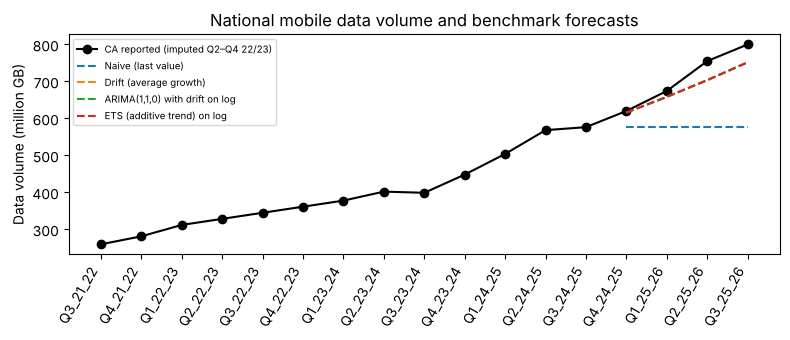

In [8]:
y_nat = national.values   # national data volume (GB) for quarters 0..16, as a numpy array
# Split by time: quarters 0..12 for fitting and 13..16 for testing. A slice [:13] stops just
# before position 13, so TRAIN_MAX_Q + 1 is needed to include quarter 12.
train_y, test_y = y_nat[:TRAIN_MAX_Q + 1], y_nat[TRAIN_MAX_Q + 1:]
h = len(test_y)   # forecast horizon: 4 quarters
# Dictionary {model name: array of h forecasts}.
nat_fc = {
    # Naive: repeat the last training value h times.
    'Naive (last value)': np.repeat(train_y[-1], h),
    # Drift: last value x exp(average log growth x number of steps ahead, 1..h).
    'Drift (average growth)': train_y[-1] * np.exp(np.mean(np.diff(np.log(train_y))) * np.arange(1, h + 1)),
    # ARIMA on log volume. With d = 1, trend='t' acts as a constant drift in the growth.
    # .fit() estimates the parameters by maximum likelihood, .forecast(h) predicts h steps
    # ahead, and np.exp converts the forecasts back from logs to GB.
    'ARIMA(1,1,0) with drift on log': np.exp(ARIMA(np.log(train_y), order=(1, 1, 0), trend='t').fit().forecast(h)),
    # Holt's linear-trend exponential smoothing on log volume, converted back with np.exp.
    'ETS (additive trend) on log': np.exp(ExponentialSmoothing(np.log(train_y), trend='add').fit().forecast(h)),
}
# MAPE (%) of each forecast against the 4 actual test values: one row per model.
nat_tab = pd.DataFrame([{'Model': k, 'MAPE_%': 100 * np.mean(np.abs(v - test_y) / test_y)} for k, v in nat_fc.items()]).round(2)
print("Table 4.13: National benchmark forecasts, test quarters 13-16")
display(save_table(nat_tab, '4.13', 'national_forecasts'))

# Figure 4.6: the reported national series and the four forecasts.
fig, ax = plt.subplots(figsize=(8, 3.5))   # one plotting area, 8 x 3.5 inches
qlabels = panel.groupby('q_idx')['Quarter'].first().values   # quarter labels, reused later
# 'k-o' = black line with circle markers; dividing by 1e6 gives million GB.
ax.plot(qlabels, y_nat / 1e6, 'k-o', label='CA reported (imputed Q2–Q4 22/23)')
for k, v in nat_fc.items():   # each forecast as a dashed line over the test quarters only
    ax.plot(qlabels[TRAIN_MAX_Q + 1:], v / 1e6, '--', label=k)
ax.set_ylabel('Data volume (million GB)'); ax.set_title('National mobile data volume and benchmark forecasts')
# Rotate the quarter labels so they do not overlap; tight_layout() fits it all in the frame.
plt.xticks(rotation=60, ha='right'); ax.legend(fontsize=7); plt.tight_layout()
# save_figure writes Outputs/figures/F4.06_national_benchmark_forecasts.png;
# plt.show() then displays the figure.
save_figure('4.06', 'national_benchmark_forecasts'); plt.show()

## Step 5: Evaluation Helpers
**What this step does.** It defines two small functions, `evaluate` and `record`, so that every model in the notebook is scored on the same test samples with the same metrics. Nothing is printed here; the functions are used from Step 6 onwards.

- Classification: ROC-AUC, PR-AUC, F1, precision, recall, balanced accuracy (threshold 0.5) and Brier score.
- Regression: MAE and RMSE of the gap on **actually stressed** cases (conditional magnitude), and MAE of the **expected gap** $\hat p \cdot \hat g$ over all cases (the hurdle combination). Relative MAE divides by the persistence MAE, a scaled error comparable across models (MASE-style).

**Classification metrics.** Each model gives every sample a score or probability $\hat p$ of being stressed next quarter.
- **ROC-AUC** (area under the receiver operating characteristic curve): the probability that a randomly chosen stressed sample gets a higher score than a randomly chosen unstressed one. 0.5 is no better than chance and 1 is a perfect ranking. It uses only the ranking of the scores, so it also works for scores that are not probabilities, such as the persistence score.
- **PR-AUC** (area under the precision–recall curve, computed as *average precision*): summarises precision over all levels of recall. It concentrates on the stressed class, so it is more informative than ROC-AUC when positives are a minority, as here. A model that guesses at random scores about the share of positives.
- **Precision**: of the samples predicted stressed, the share that really are stressed. **Recall** (sensitivity): of the samples that really are stressed, the share the model catches. **F1**: the harmonic mean of precision and recall. These three need a yes/no prediction, made by calling a sample stressed when $\hat p \ge 0.5$.
- **Balanced accuracy**: the average of the recall on stressed samples and the recall on unstressed samples (sensitivity and specificity), so the large unstressed class cannot dominate it.
- **Brier score**: the mean of $(\hat p - y)^2$, the mean squared error of the predicted probability. 0 is perfect and lower is better. It rewards probabilities that are well calibrated, so it is computed only for models that output real probabilities.

**Regression metrics** (on the gap in TB, not on the log scale).
- **MAE** (mean absolute error) $= \frac{1}{n}\sum_i |g_i - \hat g_i|$: the average size of the error, in TB.
- **RMSE** (root mean squared error) $= \sqrt{\frac{1}{n}\sum_i (g_i - \hat g_i)^2}$: like MAE but squares the errors first, so large errors weigh more. RMSE is always at least as large as MAE, and a big difference between them points to a few large misses.
- The **conditional gap** $\hat g$ is the predicted gap *if* the sub-county is stressed (from the second part of a hurdle model or the regression head of a network). The **expected gap** $\hat p \cdot \hat g$ multiplies it by the stress probability, combining both parts into one forecast of the gap for every sample.

**How the code does it.**
- `evaluate(name, p, y_bin_hat, g_cond, g_exp, idx, prob)` takes predictions for the samples in `idx` and returns one dictionary of metrics, which becomes one row of the results table.
- `record(name, p, g_cond, prob, y_bin_hat)` takes a model's predictions for **all** samples, keeps only the test rows (`test_idx`), turns the probabilities into yes/no at 0.5 (unless a ready-made yes/no prediction is passed, as for the naive baselines), computes the expected gap, and stores the metrics in the list `results` and the test predictions in the dictionary `preds`. `preds` is reused later for the hypothesis tests, the strata, the calibration plot and the saved predictions.

In [9]:
# Score one model on the samples in idx (record() below always passes test_idx).
#   p         : stress score or probability for each sample
#   y_bin_hat : yes/no stress prediction (0/1)
#   g_cond    : predicted gap if stressed (TB);  g_exp : expected gap (TB)
#   prob      : True if p is a real probability (needed for the Brier score)
def evaluate(name, p, y_bin_hat, g_cond, g_exp, idx, prob=True):
    yt, gt = y_c[idx], y_g[idx]   # the true stress labels and true gaps of these samples
    pos = yt == 1                 # boolean mask: True for the samples that really are stressed
    return {
        'Model': name,
        # Ranking metrics use the continuous score p.
        'ROC_AUC': roc_auc_score(yt, p), 'PR_AUC': average_precision_score(yt, p),
        # Threshold metrics use the 0/1 prediction. zero_division=0 returns 0 (instead of a
        # warning) if a model predicts no stressed samples at all.
        'F1': f1_score(yt, y_bin_hat), 'Precision': precision_score(yt, y_bin_hat, zero_division=0),
        'Recall': recall_score(yt, y_bin_hat), 'Balanced_Acc': balanced_accuracy_score(yt, y_bin_hat),
        'Brier': brier_score_loss(yt, p) if prob else np.nan,   # NaN = not defined for scores
        # Gap errors on the truly stressed samples only (gt[pos] keeps those rows).
        'MAE_stressed_TB': np.mean(np.abs(gt[pos] - g_cond[pos])),
        'RMSE_stressed_TB': np.sqrt(np.mean((gt[pos] - g_cond[pos]) ** 2)),
        # Expected-gap error over ALL samples (the true gap is 0 for unstressed samples).
        'MAE_expected_TB': np.mean(np.abs(gt - g_exp)),
    }

# results: a list of metric dictionaries, one per model, turned into a table later.
# preds: a dictionary {model name: test predictions}, reused by the later steps.
results, preds = [], {}

# Store one model's test performance. p and g_cond cover ALL samples; record() keeps only
# the test rows, so every model is scored on exactly the same samples.
def record(name, p, g_cond, prob=True, y_bin_hat=None):
    p_test, g_test = p[test_idx], g_cond[test_idx]
    # Yes/no prediction: threshold at 0.5, or use the 0/1 prediction passed in, if any.
    # (p_test >= 0.5) gives True/False; .astype(int) turns it into 1/0.
    yb = (p_test >= 0.5).astype(int) if y_bin_hat is None else y_bin_hat[test_idx]
    # Expected gap = probability x conditional gap (hurdle). For baselines whose score is
    # not a probability, the gap prediction is used as it is.
    g_exp = p_test * g_test if prob else g_test
    results.append(evaluate(name, p_test, yb, g_test, g_exp, test_idx, prob))
    preds[name] = {'p': p_test, 'g_cond': g_test, 'g_exp': g_exp}

## Step 6: Naive and Statistical Baselines
**Why baselines.** A complex model is only worth using if it beats simple rules. Baselines set that bar: if the GRU-MTL cannot beat "next quarter looks like this quarter", its extra complexity is not justified.

- **Persistence:** next quarter equals this quarter (score = current relative ratio; gap = current gap). This is the standard benchmark for short-term forecasting and is hard to beat when conditions change slowly.
- **Seasonal-naive:** next quarter equals the same quarter one year earlier. It would capture any pattern that repeats within the year.
- **Logistic regression + two-part log-linear regression (hurdle model):** a logit for stress occurrence and an OLS on $\ln(1+\text{gap})$ for stressed cases, retransformed with Duan's smearing estimator. This is the classical statistical counterpart of the two-head GRU-MTL.

**The hurdle (two-part) model in more detail.** Because the gap has so many exact zeros, it is modelled in two parts:
1. *Does stress occur?* A **logistic regression (logit)** estimates $\hat p = P(\text{stressed next quarter})$ from the 16 features in `tab`.
2. *How large is the gap, given stress?* An **OLS** regression of $\ln(1+\text{gap})$ on the same features, fitted only on development samples that were actually stressed.

The two parts are combined as the expected gap $\hat p \times \hat g$. The GRU-MTL has the same structure: its classification head plays the role of the logit and its regression head the role of the OLS part.

**Duan's smearing estimator.** Predicting on the log scale and then taking the exponential underestimates the mean, because $E[e^{u}] > e^{E[u]}$ for a random error $u$ (Jensen's inequality). Duan's smearing multiplies the back-transformed prediction by the average of $\exp(\text{residual})$ over the training data, which corrects this without assuming normally distributed errors.

**How the code does it.** Persistence and seasonal-naive only look up values already stored in the arrays; nothing is fitted. For the logit and OLS, the 16 features are standardised with a `StandardScaler` fitted on development rows only (`sc_tab`), so no test information leaks into the scaling. Each model's predictions for all samples are then passed to `record`.

**How to read the output.** The last line displays the results table so far: one row per model and one column per metric from Step 5. `Brier` is empty (NaN) for persistence and seasonal-naive because their scores are not probabilities. The same number of sub-counties is stressed in every quarter (the top 20%), so the two naive rules predict exactly as many stressed cases as there really are; for them precision, recall and F1 are therefore equal.

In [10]:
# Persistence: score = current relative ratio (feature 0 at the last step of the window),
# yes/no = current stress label, gap = current gap. YC[ii, tt] reads each sample's value in
# its current quarter t.
pers_score, pers_bin, pers_gap = seq[:, -1, 0], YC[ii, tt], YG[ii, tt]
# prob=False: the score is a ratio, not a probability; y_bin_hat supplies the yes/no rule.
record('Persistence', pers_score, pers_gap, prob=False, y_bin_hat=pers_bin)
# Seasonal-naive: the same quarter one year before the target. The target is t + 1, so one
# year earlier is t - 3, which is also the first (oldest) step of the window, seq[:, 0, 0].
seas_score, seas_bin, seas_gap = seq[:, 0, 0], YC[ii, tt - 3], YG[ii, tt - 3]
record('Seasonal-naive', seas_score, seas_gap, prob=False, y_bin_hat=seas_bin)

# Standardise the 16 tabular features: fit (learn each column's mean and sd) on development
# rows only, then transform all rows with those same numbers.
sc_tab = StandardScaler().fit(tab.iloc[train_idx])
Xtab = sc_tab.transform(tab)
# Logistic regression for P(stressed next quarter), fitted on development rows. max_iter=2000
# gives the solver enough iterations to converge; scikit-learn adds a mild L2 penalty
# (C = 1.0) by default.
logit = LogisticRegression(max_iter=2000).fit(Xtab[train_idx], y_c[train_idx])
# predict_proba returns two columns, P(class 0) and P(class 1); [:, 1] keeps P(stressed).
p_logit = logit.predict_proba(Xtab)[:, 1]
# Row numbers of the development samples that were actually stressed (gap part only).
pos_tr = train_idx[y_c[train_idx] == 1]
# OLS of ln(1 + gap) on the features plus an intercept, using stressed development rows.
ols = sm.OLS(log_g[pos_tr], sm.add_constant(Xtab[pos_tr])).fit()
smear = np.mean(np.exp(ols.resid))   # Duan's smearing factor: mean of exp(residuals)
# Back-transform: exp(prediction) x smearing factor - 1 undoes ln(1 + gap).
# np.clip(..., 0, None) sets any negative value to 0, because a gap cannot be negative.
g_hurdle = np.clip(np.exp(ols.predict(sm.add_constant(Xtab))) * smear - 1, 0, None)
record('Logit + two-part regression (hurdle)', p_logit, g_hurdle)
# A bare expression on the last line of a cell is displayed by Jupyter: the results so far.
pd.DataFrame(results).round(4)

,Model,ROC_AUC,PR_AUC,F1,Precision,Recall,Balanced_Acc,Brier,MAE_stressed_TB,RMSE_stressed_TB,MAE_expected_TB
0,Persistence,0.9552,0.8996,0.8347,0.8347,0.8347,0.8966,NaN,76.4954,117.1948,19.2659
1,Seasonal-naive,0.8622,0.7491,0.6992,0.6992,0.6992,0.8118,NaN,115.5666,180.8086,40.2957
2,Logit + two-part regression (hurdle),0.9799,0.9366,0.8305,0.8305,0.8305,0.8940,0.048,80.5675,125.6235,23.0923


## Step 7: Tree Ensembles (Two-Part XGBoost and LightGBM)
**What gradient boosting is.** A decision tree predicts by asking a sequence of yes/no questions about the features (for example, "is `rel_ratio` above some value?"). **Gradient boosting** builds many small trees one after another. Each new tree is fitted to the remaining errors of the trees before it (more precisely, to the gradient of the loss function), and its contribution is shrunk by a **learning rate** so that the model improves in small steps. The prediction is the sum over all trees. Boosted trees pick up non-linear effects and interactions between features automatically and are a strong standard method for tabular data, which makes them the main machine-learning baseline here.

**XGBoost and LightGBM** are two widely used implementations. XGBoost limits each tree by its depth (`max_depth`, the number of questions in a row); LightGBM grows each tree leaf by leaf and limits the number of leaves (`num_leaves`). Trees split on thresholds, so the features do not need to be standardised.

Classifier on all samples; regressor on $\ln(1+\text{gap})$ for stressed samples only (same hurdle logic). XGBoost depth and number of trees are chosen on the rolling-origin folds by validation PR-AUC.

**How the tuning works.** The grid is `max_depth` ∈ {2, 3, 5} × `n_estimators` (number of trees) ∈ {200, 400}, six combinations. For each one the classifier is trained on fold 1 (targets ≤ 8) and scored on quarters 9–10, then trained on fold 2 (targets ≤ 10) and scored on quarters 11–12, and the two validation PR-AUCs are averaged. PR-AUC is the tuning criterion because stress is the minority class. The settings in `XGB_FIXED` (learning rate 0.05, row subsample 0.8, column subsample 0.8) are not tuned. LightGBM is not tuned either: it uses fixed settings (300 trees, learning rate 0.05, 15 leaves, 0.8 row and column subsampling).

**How to read the output.** Table 4.14 lists the six XGBoost settings sorted by mean validation PR-AUC; the top row is the setting used for the final XGBoost model (`XGB_DEPTH`, `XGB_N`). The table after it is the updated results table, with the two tree models added below the Step 6 baselines.

In [11]:
# Fit one two-part XGBoost model on the rows `tr`:
#   clf = classifier for stress (all rows in tr),
#   reg = regressor for ln(1 + gap) (only the stressed rows in tr).
# The raw `tab` features are used, since trees do not need standardised inputs.
def fit_xgb_pair(tr, depth, n_est, seed=42):
    # max_depth = maximum depth of each tree; n_estimators = number of trees.
    # **XGB_FIXED unpacks the dictionary into keyword arguments (learning_rate=0.05,
    # subsample=0.8, colsample_bytree=0.8). eval_metric names the metric XGBoost reports when
    # it evaluates; no evaluation set is passed here, so it does not change the fitted trees.
    clf = xgb.XGBClassifier(max_depth=depth, n_estimators=n_est, **XGB_FIXED, random_state=seed, eval_metric='logloss')
    clf.fit(tab.iloc[tr], y_c[tr])   # .iloc selects table rows by position
    pos = tr[y_c[tr] == 1]           # the stressed rows within tr
    reg = xgb.XGBRegressor(max_depth=depth, n_estimators=n_est, **XGB_FIXED, random_state=seed)
    reg.fit(tab.iloc[pos], log_g[pos])   # squared-error regression on ln(1 + gap)
    return clf, reg

# Tuning grid: every combination of depth and number of trees (a list of 6 pairs).
grid = [(d, n) for d in [2, 3, 5] for n in [200, 400]]
cv = []
for d, n in grid:
    scores = []
    # FOLDS = [(8, (9, 10)), (10, (11, 12))]: train on targets up to tr_max, validate on val_q.
    for tr_max, val_q in FOLDS:
        # np.isin(tq, val_q) is True where the target quarter is a validation quarter.
        tr = np.where(tq <= tr_max)[0]; va = np.where(np.isin(tq, val_q))[0]
        clf, _ = fit_xgb_pair(tr, d, n)   # only the classifier is needed for tuning
        scores.append(average_precision_score(y_c[va], clf.predict_proba(tab.iloc[va])[:, 1]))
    cv.append({'max_depth': d, 'n_estimators': n, 'val_PR_AUC': np.mean(scores)})   # fold mean
cv = pd.DataFrame(cv).sort_values('val_PR_AUC', ascending=False)   # best setting first
print("Table 4.14: XGBoost tuning by rolling-origin validation")
display(save_table(cv.round(4), '4.14', 'xgb_tuning'))
# Take the best (first) row; int() turns the stored numbers back into whole numbers.
XGB_DEPTH, XGB_N = int(cv.iloc[0]['max_depth']), int(cv.iloc[0]['n_estimators'])

# Refit the chosen setting on the whole development period and predict every sample.
xgb_clf, xgb_reg = fit_xgb_pair(train_idx, XGB_DEPTH, XGB_N)
p_xgb = xgb_clf.predict_proba(tab)[:, 1]   # P(stressed)
# The regressor predicts ln(1 + gap); np.expm1(x) = exp(x) - 1 undoes np.log1p, and negative
# values are clipped to 0. (Unlike the OLS part in Step 6, no smearing factor is applied.)
g_xgb = np.clip(np.expm1(xgb_reg.predict(tab)), 0, None)
record('XGBoost (two-part)', p_xgb, g_xgb)

# LightGBM with fixed (untuned) settings: num_leaves = maximum leaves per tree;
# subsample=0.8 with subsample_freq=1 draws 80% of the rows for every tree;
# colsample_bytree=0.8 draws 80% of the features per tree; verbose=-1 hides training messages.
lgb_params = dict(n_estimators=300, learning_rate=0.05, num_leaves=15, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, random_state=42, verbose=-1)
# .fit() returns the fitted model itself, so fitting and storing happen in one line.
# Classifier on all development rows; regressor on the stressed development rows (pos_tr).
lgb_clf = lgb.LGBMClassifier(**lgb_params).fit(tab.iloc[train_idx], y_c[train_idx])
lgb_reg = lgb.LGBMRegressor(**lgb_params).fit(tab.iloc[pos_tr], log_g[pos_tr])
record('LightGBM (two-part)', lgb_clf.predict_proba(tab)[:, 1], np.clip(np.expm1(lgb_reg.predict(tab)), 0, None))
pd.DataFrame(results).round(4)   # results table with all five non-neural models

Table 4.14: XGBoost tuning by rolling-origin validation
[saved] Outputs/tables/T4.14_xgb_tuning.csv


,max_depth,n_estimators,val_PR_AUC
0,2,200,0.9410
1,2,400,0.9406
2,3,200,0.9393
3,3,400,0.9385
4,5,200,0.9339
5,5,400,0.9321


,Model,ROC_AUC,PR_AUC,F1,Precision,Recall,Balanced_Acc,Brier,MAE_stressed_TB,RMSE_stressed_TB,MAE_expected_TB
0,Persistence,0.9552,0.8996,0.8347,0.8347,0.8347,0.8966,NaN,76.4954,117.1948,19.2659
1,Seasonal-naive,0.8622,0.7491,0.6992,0.6992,0.6992,0.8118,NaN,115.5666,180.8086,40.2957
2,Logit + two-part regression (hurdle),0.9799,0.9366,0.8305,0.8305,0.8305,0.8940,0.0480,80.5675,125.6235,23.0923
3,XGBoost (two-part),0.9807,0.9375,0.8390,0.8390,0.8390,0.8993,0.0460,77.6330,134.1893,20.3316
4,LightGBM (two-part),0.9815,0.9391,0.8367,0.8071,0.8686,0.9083,0.0491,78.3983,132.2787,20.4156


## Step 8: Neural Architectures
**Neural network basics.** A neural network is a flexible function built from layers. A **linear layer** computes weighted sums of its inputs; an **activation function** such as ReLU, $\max(0, x)$, makes the function non-linear. The weights are learned by repeatedly adjusting them to reduce a loss function (gradient descent). In PyTorch every model is a class that inherits from `nn.Module`: the layers are created in `__init__`, and the method `forward()` describes how an input flows through them to give the output.

**Recurrent networks (GRU and LSTM).** A recurrent neural network reads a sequence one time step at a time and carries a **hidden state**, a vector of numbers (of length `hidden`) that summarises what it has read so far. At each quarter the hidden state is updated from the previous hidden state and the new quarter's features. After the fourth (current) quarter, the final hidden state is the network's summary of the whole window.
- **GRU (gated recurrent unit):** uses two learned *gates*, an update gate and a reset gate, which decide how much of the old memory to keep and how much new information to let in. This lets it carry useful patterns across several quarters.
- **LSTM (long short-term memory):** an older and slightly larger design with three gates and a separate memory cell. It is included as an alternative encoder, to check whether the choice of GRU matters.

**Sequence models** (GRU or LSTM encoder, 1 layer). Static covariates are concatenated **after** the encoder (proposal Section 3.4.3), then fed to:
- a **classification head** (stress probability, binary cross-entropy), and/or
- a **regression head** (standardised $\ln(1+\text{gap})$, Huber loss **masked** to stressed samples).

Each head is a small network: a linear layer to 32 units, ReLU, **dropout** of 10%, and a linear layer to one output. Dropout switches off each unit with probability 10% at every training step (only during training, not when predicting), which reduces overfitting. The classification head outputs a *logit* (a log-odds score), and the sigmoid function $1/(1+e^{-x})$ turns it into a probability. The `mode` argument chooses the heads: `'mtl'` gives both (multi-task), `'cls'` only the stress head and `'reg'` only the gap head (the last two are the single-task GRUs used for H1).

**The multi-task loss** that training minimises:

$$\mathcal{L} = \mathcal{L}_{\text{BCE}} + \lambda \cdot \frac{\sum_i \mathbb{1}(y_i=1)\,\text{Huber}(\hat r_i, r_i)}{\sum_i \mathbb{1}(y_i=1)}$$

In words: the **binary cross-entropy** of the stress prediction (the log-loss, which logistic regression also minimises) plus $\lambda$ times the average **Huber loss** of the gap prediction over the stressed samples only. Here $r_i$ is the standardised $\ln(1+\text{gap})$ and $\hat r_i$ its prediction. The indicator $\mathbb{1}(y_i=1)$ is the **mask**: unstressed samples have no gap to learn, so they contribute nothing to the regression part, just as the OLS part of the hurdle model is fitted on stressed rows only. The Huber loss behaves like squared error for small errors and like absolute error for large ones, so a few very large gaps do not dominate training. The weight $\lambda$ sets the balance between the two tasks and is tuned later. Standardising the regression target (using the mean and standard deviation of the stressed training rows) keeps the two loss terms on comparable scales.

**T-GCN** (Zhao et al., 2020): at each quarter a graph convolution $Z_t = \text{ReLU}(\hat A X_t W)$ over the 5-nearest-neighbour graph ($\hat A = D^{-1/2}(A+I)D^{-1/2}$) aggregates neighbouring sub-counties before the GRU. It receives no hand-made spatial-lag features, so it must learn spatial structure itself.

**What the graph convolution does.** The sub-counties are the nodes of a graph, with an edge between two sub-counties when either is among the other's 5 nearest neighbours ($A$). In each quarter, $X_t$ holds every sub-county's features; they are first multiplied by a learned weight matrix $W$ (16 output features), and $\hat A$ then replaces each sub-county's result by a weighted sum over itself and its neighbours, followed by ReLU. Adding $I$ (self-loops) keeps each sub-county's own information in the sum, and dividing by the square root of the number of connections ($D^{-1/2}$ on both sides, where $D$ is the diagonal matrix of row sums of $A+I$) stops well-connected sub-counties from getting larger values just because they have more neighbours. In this implementation the GRU receives both the graph-convolved features and the sub-county's own features at each quarter. Because the graph convolution combines all sub-counties of a quarter, T-GCN processes one whole quarter (all 294 sub-counties) at a time.

**How the code does it.** The classes `SeqNet` and `TGCN` are defined in `project_config.py`; the cell prints their source code so the exact architectures are visible here. It then builds `A_HAT`, the normalised adjacency matrix $\hat A$ that T-GCN uses.

In [12]:
# SeqNet and TGCN are defined once in project_config.py, so Notebook 05 rebuilds exactly the same networks.
# inspect.getsource() fetches the source code of a class as text, and textwrap.dedent()
# removes the extra indentation (the classes sit inside a try-block in project_config.py).
print(textwrap.dedent(inspect.getsource(SeqNet)))
print(textwrap.dedent(inspect.getsource(TGCN)))

# ---- Normalised adjacency matrix for T-GCN: A_hat = D^(-1/2) (A + I) D^(-1/2) ------------
# W_knn is not symmetric (j can be among i's 5 nearest without i being among j's), so the
# graph links i and j if EITHER is a neighbour of the other ('|' is element-wise OR).
# .astype(float) turns True/False into 1.0/0.0, and np.eye(N) adds the self-loops (+ I).
A = ((W_knn > 0) | (W_knn.T > 0)).astype(float) + np.eye(N)
dinv = np.diag(1 / np.sqrt(A.sum(1)))   # D^(-1/2): diagonal of 1/sqrt(row sums of A + I)
# Symmetric normalisation, stored as a PyTorch tensor (32-bit floats, PyTorch's usual
# precision) because the network multiplies it with its features during training.
A_HAT = torch.tensor(dinv @ A @ dinv, dtype=torch.float32)

class SeqNet(nn.Module):
    """GRU/LSTM encoder; static covariates concatenated after the encoder; optional
    classification head (stress) and regression head (log load gap)."""
    # f_dyn / f_stat: number of time-varying / static features; hidden: size of the GRU or
    # LSTM memory; cell: 'gru' or 'lstm'; mode: 'mtl' = both heads, 'cls' = stress head
    # only, 'reg' = gap head only.
    def __init__(self, f_dyn, f_stat, hidden=32, cell='gru', mode='mtl'):
        super().__init__()
        # batch_first=True: the input is shaped (sub-county windows, quarters, features).
        self.rnn = (nn.GRU if cell == 'gru' else nn.LSTM)(f_dyn, hidden, batch_first=True)
        d = hidden + f_stat              # encoder output + static covariates
        # A head: d -> 32 units -> ReLU -> dropout (10% of values zeroed while training,
        # against overfitting) -> 1 output. The lambda builds a new head with its own
        # weights on each call. A head not needed in this mode is None

**How to read the printed code.**
- `class SeqNet(nn.Module)` defines the GRU and LSTM models. In `__init__`, `self.rnn` is the recurrent encoder: `nn.GRU` or `nn.LSTM` with `f_dyn` input features and `hidden` units. `batch_first=True` means the input has the shape (samples, time steps, features), the same layout as `seq`. `d = hidden + f_stat` is the length of the vector after the static features are appended. `head` is a small recipe (a `lambda`) that builds one head, `Linear(d, 32) → ReLU → Dropout(0.1) → Linear(32, 1)`. `self.cls` and `self.reg` are the two heads; a head is `None` when the chosen `mode` does not use it.
- `encode()` runs the encoder. `self.rnn(xd)` returns the hidden state at every time step (`out`) together with the final state, which is not needed (`_`). `out[:, -1, :]` keeps the hidden state after the last quarter, and `torch.cat([...], dim=1)` appends the static features `xs` to it.
- `forward()` is what runs when the model is called as `model(xd, xs)`. It returns a pair: the stress logit and the standardised log-gap prediction, with `None` for a head that is not used. `.squeeze(1)` turns a column of shape (samples, 1) into a flat vector of shape (samples,).
- `class TGCN(SeqNet)` **inherits** from `SeqNet`: it reuses the GRU and the two heads and replaces only `encode()`. `super().__init__(gc_dim + f_dyn, ...)` builds a GRU whose input is the 16 graph-convolved features plus the original features, always in multi-task mode. `register_buffer('A', A_hat)` stores $\hat A$ inside the model as a fixed tensor that is not trained. In `encode()`, `self.gc(xd)` is the linear layer that plays the role of $W$, and `torch.einsum('ij,jlf->ilf', self.A, ...)` multiplies $\hat A$ with the features at every time step $l$: for each sub-county $i$ it sums over the sub-counties $j$. This computes $\hat A X_t W$ for all four quarters of the window at once. `torch.cat([z, xd], dim=-1)` then joins the graph features `z` with the original features before the GRU.

The training routine that follows turns these classes into fitted models.

### Training routine
This cell defines `train_net`, the single function that trains **every** neural model in this notebook: GRU-MTL, GRU-MTL without spatial lags, LSTM-MTL, T-GCN and the two single-task GRUs. The hyperparameter search, the final models, the county holdout, the conformal intervals and the final refit all call it, so it is worth understanding once.

**Terms used below**
- **Epoch:** one full pass of the network through all training samples. The samples are split into **mini-batches** of 128, and the weights are updated once after each batch, so one epoch contains many small updates.
- **Learning rate:** how large each weight update is. It is fixed at 0.001 with the Adam optimiser (a widely used default). A rate that is too large makes training jump around; one that is too small makes it very slow.
- **Seed:** the starting value of the random-number generator. It fixes the random starting weights, the order in which samples are shuffled and the dropout pattern, so the same seed always reproduces the same model.
- **Early stopping:** after every epoch the model is scored on validation quarters that it is not trained on, and training stops once the validation loss stops improving. This guards against **overfitting**, where the network memorises the training quarters instead of learning patterns that carry over to new quarters.

**What `train_net` does, step by step**
1. **Scaling.** `StandardScaler` rescales every input feature to mean 0 and standard deviation 1, so that no feature dominates just because of its units. Scalers and the regression-target standardisation are fitted on the training rows of each run only (no look-ahead), so nothing from the validation or test quarters leaks into training.
2. **Regression target.** The gap head predicts $\ln(1+\text{gap})$, standardised with the mean (`gmu`) and standard deviation (`gsd`) of the **stressed** training rows, because only stressed rows enter the gap loss.
3. **Network and optimiser.** The network is built from the `TGCN` or `SeqNet` class (project_config.py) and trained with Adam, using learning rate 0.001 and weight decay 0.0001 (a small penalty that stops the weights from growing too large).
4. **Multi-task loss** (`loss_fn`): binary cross-entropy for the stress head plus λ times the Huber loss of the gap head, where the Huber loss is averaged over stressed samples only (the formula in Step 8). A single-task model uses only the loss of the one head it has.
5. **Training loop.** In every epoch the samples are shuffled, and for each mini-batch the code clears the old gradients, makes predictions, computes the loss, back-propagates it (works out how each weight should change to reduce the loss), limits the size of the gradients and updates the weights. T-GCN is the exception to the mini-batches: one batch is one target quarter containing all sub-counties, because the graph convolution needs every neighbour to be present.
6. **Early stopping.** With early stopping, training stops when the validation loss has not improved for 15 epochs and the best epoch is recorded. The validation loss is the same combined loss, computed on the validation quarters. The weights from the best epoch are restored before any prediction is made, and training is capped at 200 epochs.
7. **Final models.** Final models are retrained on the whole development period for the averaged best number of epochs. They are called with a fixed `epochs=` value and no validation set, so early stopping is switched off and the weights after the last epoch are used.

**What it returns:** a dictionary with `best_epoch` and a `predict` function. `predict(idx)` gives three arrays for the samples whose row numbers are in `idx`: the stress probability, the predicted gap in TB (converted back from the log scale and floored at 0), and the same gap prediction on the $\ln(1+\text{gap})$ scale, which Step 12 uses for the conformal intervals. With `return_model=True` the trained network and its scalers are returned as well, so Step 13 can save them for Notebook 05.

In [13]:
# train_net trains one neural model and returns a dictionary that includes predict().
#   spec         : dictionary describing the model (kind, cell, mode, hidden, lambda, inputs)
#   tr, va       : row numbers (indices) of the training and the validation samples
#   epochs       : None -> train with early stopping on va; a number -> train exactly that long
#   seed         : random seed, so that each run can be reproduced exactly
#   max_epochs   : upper limit on epochs in early-stopping mode
#   patience     : epochs without improvement before early stopping gives up
#   return_model : also hand back the trained network and its scalers (needed in Step 13)
def train_net(spec, tr, va=None, epochs=None, seed=0, max_epochs=200, patience=15, return_model=False):
    # Fix both random generators: torch (starting weights, dropout) and numpy (shuffling)
    torch.manual_seed(seed); np.random.seed(seed)
    # Dynamic feature columns this model sees (all of ALL_DYN, or only the non-spatial ones)
    cols = spec['dyn_cols']
    F = len(cols)                                    # number of dynamic features used
    # Fit the input scalers on TRAINING rows only (no look-ahead). seq has shape
    # (samples, L quarters, features); reshape(-1, F) stacks all samples and quarters into one
    # long table with F columns, so each feature gets a single mean and standard deviation.
    sd = StandardScaler().fit(seq[tr][:, :, cols].reshape(-1, F))
    ss = StandardScaler().fit(stat[tr])              # same idea for the static covariates
    # Mean and sd of the regression target ln(1+gap), from the stressed training rows only
    pos = tr[y_c[tr] == 1]
    gmu, gsd = log_g[pos].mean(), log_g[pos].std()
    # to_t ("to tensors") turns a set of row indices into the four PyTorch tensors the network
    # needs: scaled sequences (n, L, F), scaled static covariates, stress label (0/1) and the
    # standardised log-gap. A lambda is a short unnamed function, used here as a shortcut.
    # Tensors are PyTorch's arrays; float32 is the number type the network works with.
    to_t = lambda idx: (torch.tensor(sd.transform(seq[idx][:, :, cols].reshape(-1, F)).reshape(len(idx), L, F), dtype=torch.float32),
                        torch.tensor(ss.transform(stat[idx]), dtype=torch.float32),
                        torch.tensor(y_c[idx], dtype=torch.float32),
                        torch.tensor((log_g[idx] - gmu) / gsd, dtype=torch.float32))
    # Build the network: T-GCN (graph convolution + GRU) or a GRU/LSTM sequence model.
    # Both classes are defined in project_config.py; len(STAT) = number of static covariates.
    if spec['kind'] == 'tgcn':
        model = TGCN(F, len(STAT), A_HAT, hidden=spec['hidden'])
    else:
        model = SeqNet(F, len(STAT), spec['hidden'], spec['cell'], spec['mode'])
    # Adam optimiser, learning rate 0.001; weight_decay adds a small penalty on large weights
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    # BCEWithLogitsLoss = sigmoid + binary cross-entropy in one numerically stable step; it
    # takes the raw score ("logit"), not a probability. HuberLoss acts like squared error for
    # small errors and like absolute error for large ones, so extreme gaps do not dominate.
    # reduction='none' keeps one loss per sample so that non-stressed samples can be masked.
    bce, hub = nn.BCEWithLogitsLoss(), nn.HuberLoss(reduction='none')
    # Lambda = weight of the gap loss relative to the stress loss (1.0 if the spec gives none)
    lam = spec.get('lam', 1.0)

    # Combined multi-task loss. c and r are the outputs of the stress head and the gap head;
    # yc and yr are the true stress label and the true standardised log-gap. A single-task
    # model returns None for the head it does not have, and that part of the loss is skipped.
    def loss_fn(c, r, yc, yr):
        loss = 0.0
        if c is not None:
            loss = loss + bce(c, yc)                 # stress task: binary cross-entropy
        if r is not None:
            m = yc                                   # mask: 1 if stressed, 0 otherwise
            # Huber loss averaged over the stressed samples only; the 1e-8 avoids dividing by
            # zero when a batch happens to contain no stressed sample
            lr_ = (hub(r, yr) * m).sum() / (m.sum() + 1e-8)
            # Multi-task model: gap loss weighted by lambda; single-task gap model: weight 1
            loss = loss + (lam if c is not None else 1.0) * lr_
        return loss

    # Split a set of rows into batches; shuffle=True gives a new random order every epoch
    def batches(idx, shuffle):
        if spec['kind'] == 'tgcn':                  # one batch = all sub-counties in one target quarter
            # The graph convolution multiplies by the N x N neighbour matrix A_HAT, so a batch
            # must hold every sub-county of one quarter. np.unique lists the quarters present;
            # with shuffle the order of the quarters is randomised.
            qs = np.unique(tq[idx]); qs = np.random.permutation(qs) if shuffle else qs
            return [idx[tq[idx] == q] for q in qs]
        idx = np.random.permutation(idx) if shuffle else idx   # permutation = shuffled copy
        # Consecutive chunks of 128 rows (the last chunk may be smaller)
        return [idx[i:i + 128] for i in range(0, len(idx), 128)]

    Xva = to_t(va) if va is not None else None      # validation tensors, prepared once
    # Early-stopping bookkeeping: best validation loss so far (starts at infinity), the epoch
    # it happened, epochs since the last improvement, and a copy of the best weights
    best, best_ep, wait, best_state = np.inf, 0, 0, None
    n_ep = epochs if epochs is not None else max_epochs   # fixed epochs, or at most 200
    for ep in range(1, n_ep + 1):                   # each pass of this loop is one epoch
        model.train()                               # training mode: dropout switched on
        for b in batches(tr, True):
            xd, xs, yc, yr = to_t(b)
            opt.zero_grad()                         # clear gradients left from the last batch
            c, r = model(xd, xs)                    # forward pass: stress score, gap
            # Back-propagation: compute the gradient of the loss with respect to every weight
            loss_fn(c, r, yc, yr).backward()
            # Rescale the gradients if their overall size exceeds 1.0; this guards against the
            # very large, unstable updates that recurrent networks are prone to
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()                              # move the weights one small step downhill
        if epochs is None:                          # early-stopping mode: score validation set
            model.eval()                            # evaluation mode: dropout switched off
            with torch.no_grad():                   # no gradients needed: saves time, memory
                if spec['kind'] == 'tgcn':
                    # T-GCN: average the loss over the validation quarters (one graph each).
                    # to_t(b)[:2] are the inputs, to_t(b)[2:] the labels; the * operator
                    # unpacks a tuple into separate function arguments.
                    vl = np.mean([loss_fn(*model(*to_t(b)[:2]), *to_t(b)[2:]).item() for b in batches(va, False)])
                else:
                    # .item() turns a one-number tensor into an ordinary Python float
                    vl = loss_fn(*model(*Xva[:2]), *Xva[2:]).item()
            # Count it as an improvement only if the loss falls by more than 0.0001
            if vl < best - 1e-4:
                best, best_ep, wait = vl, ep, 0
                # state_dict() is a dictionary of all weight tensors; clone() makes a real
                # copy, so later training does not overwrite the saved best weights
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= patience:                # 15 epochs without improvement: stop
                    break
    # Restore the best-epoch weights (early-stopping mode only; with a fixed number of epochs
    # best_state stays None and the weights after the last epoch are kept)
    if best_state is not None:
        model.load_state_dict(best_state)

    # predict(idx) returns (stress probability, gap in TB, gap on the ln(1+gap) scale) for the
    # rows idx. It is defined inside train_net so it can reuse this run's model and scalers.
    def predict(idx):
        model.eval()
        with torch.no_grad():
            if spec['kind'] == 'tgcn':
                # T-GCN predicts one whole quarter at a time: keep (rows, outputs) per quarter
                outs = [(b, model(*to_t(b)[:2])) for b in batches(idx, False)]
                order = np.concatenate([b for b, _ in outs])     # rows in the order predicted
                # Stack the per-quarter outputs and convert tensors to numpy arrays
                c = torch.cat([o[0] for _, o in outs]).numpy(); r = torch.cat([o[1] for _, o in outs]).numpy()
                # Put the predictions back into the order of idx: 'where' maps a row number
                # to its position in 'order', and 'take' lists those positions for idx
                where = {v: k for k, v in enumerate(order)}
                take = np.array([where[v] for v in idx])
                c, r = c[take], r[take]
            else:
                c, r = model(*to_t(idx)[:2])        # only the inputs (first two tensors)
                c = c.numpy() if c is not None else None   # tensor -> numpy array
                r = r.numpy() if r is not None else None
        # Logistic (sigmoid) function: turns the raw score into a probability between 0 and 1
        p = 1 / (1 + np.exp(-c)) if c is not None else None
        # Undo the standardisation (r * gsd + gmu), then undo ln(1 + x) with
        # expm1(x) = exp(x) - 1; clip at 0 because a gap cannot be negative
        g = np.clip(np.expm1(r * gsd + gmu), 0, None) if r is not None else None
        return p, g, (r * gsd + gmu if r is not None else None)   # third item: ln(1+gap) scale

    # Results: the best epoch found (0 when early stopping was off) and the predict function
    out = {'best_epoch': best_ep, 'predict': predict}
    if return_model:
        # Keep the network and everything needed to scale new data in exactly the same way
        out.update(model=model, scalers={'dyn': sd, 'stat': ss, 'gmu': gmu, 'gsd': gsd, 'dyn_cols': cols})
    return out

### Hyperparameter selection for GRU-MTL (rolling origin)
**What this step does.** Before the final GRU-MTL is trained, two of its **hyperparameters** (settings chosen by the analyst rather than learned from the data) are chosen by trying every combination and keeping the one that forecasts the validation quarters best.

Grid: hidden units ∈ {16, 32} × loss weight λ ∈ {0.5, 1.0}. The configuration with the highest mean validation PR-AUC across both folds is selected. Dropout (0.1), learning rate (0.001) and batch size (128) are fixed rather than tuned: with only two rolling-origin folds, a larger grid would mostly fit noise in the validation quarters. This is a declared deviation from proposal Section 3.4.3.
- **Hidden units** is the size of the GRU's internal memory. More units let the network learn more complex patterns, but also make it easier to overfit.
- **λ (lambda)** is the weight of the gap loss relative to the stress loss in the multi-task loss. With λ = 0.5 the gap task counts half as much as the stress task; with λ = 1.0 both count equally.
- **PR-AUC** is the selection criterion because only about one sample in five is stressed. PR-AUC focuses on how well the stressed cases are found and ranked, which is what matters for planning.

**Rolling-origin validation.** A forecasting model must never learn from the future. Rolling-origin (expanding-window) validation therefore trains on the early quarters and validates on the quarters that follow, then moves the forecast origin forward and repeats. The two folds are set in `FOLDS` (project_config.py): train on target quarters ≤ 8 and validate on 9–10, then train on ≤ 10 and validate on 11–12. The test quarters 13–16 are not used at all in this step.

**How the code does it.** Two nested loops go over the 4 combinations. For each one, `train_net` runs on both folds with early stopping, the validation PR-AUC and best epoch are stored, and their averages over the two folds become one row of Table 4.15. `HIDDEN` and `LAM` are then taken from the top row and reused by every later neural model.

In [14]:
# Column positions of the dynamic features. ALL_DYN = DYN + SPAT, so the first len(DYN)
# columns are the non-spatial features and the last two are the spatial-lag features.
ALL_COLS = list(range(len(ALL_DYN)))                # every dynamic feature
NOSPAT_COLS = list(range(len(DYN)))                 # without the spatial-lag features
tuning = []                                         # one dictionary per configuration
t0 = time.time()                                    # start a timer (seconds)
# Grid search: every combination of hidden size and lambda (2 x 2 = 4 configurations)
for hidden in [16, 32]:
    for lam in [0.5, 1.0]:
        spec = dict(kind='seq', cell='gru', mode='mtl', hidden=hidden, lam=lam, dyn_cols=ALL_COLS)
        pr, eps = [], []                            # validation PR-AUC and best epoch per fold
        # FOLDS = [(8, (9, 10)), (10, (11, 12))]: train on target quarters <= 8 and validate
        # on 9-10, then train on <= 10 and validate on 11-12
        for tr_max, val_q in FOLDS:
            # np.where(condition)[0] returns the row numbers where the condition is True;
            # np.isin checks whether each target quarter is one of the validation quarters
            tr = np.where(tq <= tr_max)[0]; va = np.where(np.isin(tq, val_q))[0]
            run = train_net(spec, tr, va)           # epochs not given -> early stopping on va
            # average_precision_score = PR-AUC; run['predict'](va)[0] = validation probs
            pr.append(average_precision_score(y_c[va], run['predict'](va)[0])); eps.append(run['best_epoch'])
        # One row of Table 4.15: the averages over the two folds
        tuning.append({'hidden': hidden, 'lambda': lam, 'val_PR_AUC': np.mean(pr), 'mean_best_epoch': np.mean(eps)})
# List of dictionaries -> table, best validation PR-AUC first
tuning = pd.DataFrame(tuning).sort_values('val_PR_AUC', ascending=False)
print("Table 4.15: GRU-MTL tuning by rolling-origin validation")
# save_table (project_config.py) writes the CSV to Outputs/tables/; display shows it in Jupyter
display(save_table(tuning.round(4), '4.15', 'gru_mtl_tuning'))
# Keep the settings of the top row (.iloc[0] = first row) for all later neural models
HIDDEN, LAM = int(tuning.iloc[0]['hidden']), float(tuning.iloc[0]['lambda'])
# f-string: the expressions inside {} are filled in; :.0f prints a number with no decimals
print(f"Selected: hidden={HIDDEN}, lambda={LAM} ({time.time() - t0:.0f}s)")

Table 4.15: GRU-MTL tuning by rolling-origin validation
[saved] Outputs/tables/T4.15_gru_mtl_tuning.csv


,hidden,lambda,val_PR_AUC,mean_best_epoch
2,32,0.5,0.9390,31.5
3,32,1.0,0.9383,33.5
0,16,0.5,0.9354,42.0
1,16,1.0,0.9349,42.0


Selected: hidden=32, lambda=0.5 (50s)


**How to read Table 4.15.** Each row is one combination of hidden units and λ, sorted with the best first. `val_PR_AUC` is the validation PR-AUC averaged over the two folds (higher is better, 1 is perfect), and `mean_best_epoch` is the average epoch at which early stopping found the lowest validation loss. The printed line `Selected: ...` names the configuration kept for the rest of the notebook and the time the search took. When the top rows differ only in the third decimal, the choice makes little practical difference.

### Final neural models: 5 seeds each
Every model uses the selected hidden size. Epochs come from rolling-origin early stopping per model. Metrics are reported for the **seed ensemble** (averaged predictions) and as mean ± sd across seeds.

**The six neural models** (dictionary `SPECS`)

| Model | What it is | Role in the study |
|---|---|---|
| GRU-MTL (proposed) | GRU encoder with a stress head and a gap head; all dynamic features, including the two spatial-lag features | The proposed model |
| GRU-MTL without spatial lags | The same model without the two spatial-lag features | H2: do spatial-lag features help? |
| LSTM-MTL | The same multi-task set-up with an LSTM cell instead of a GRU | Checks whether the choice of recurrent cell matters |
| T-GCN (graph conv + GRU) | Graph convolution over neighbouring sub-counties, then a GRU; no hand-made spatial lags | H2: does a graph model help? |
| Single-task GRU (stress) | GRU with only the stress head | H1: one multi-task model against separate models |
| Single-task GRU (gap) | GRU with only the gap head | H1, combined with the stress GRU as a hurdle pair |

**How the code does it**
1. `select_epochs` reruns early stopping on both rolling-origin folds and averages the two best epochs (rounded, and at least 5). This fixes how long each final model trains, because the final models have no validation quarters left to stop on.
2. Each model is then trained 5 times on all development quarters (target quarters ≤ 12), once for each seed in `SEEDS` (0 to 4), and predicts every sample.
3. A neural network starts from random weights, so two seeds give slightly different models. Averaging the 5 seeds' predictions (the **seed ensemble**) gives a more stable forecast, and the spread between seeds shows how much a single run could vary.
4. `record` (Step 5) scores the ensemble on the test quarters and adds it to the results list. `evaluate` scores each seed on its own, and those rows are collected in `seed_rows` for Table 4.17.
5. The two single-task GRUs are combined into one forecaster, **Single-task GRUs (stress + gap)**: the stress probability comes from the stress GRU and the gap from the gap GRU. This is the same hurdle logic as the two-part tree models.

In [15]:
# SPECS: one dictionary per neural model; dict(...) builds a dictionary from keyword arguments.
#   kind: 'seq' (GRU/LSTM) or 'tgcn';  cell: 'gru' or 'lstm';
#   mode: 'mtl' (both heads), 'cls' (stress head only) or 'reg' (gap head only);
#   dyn_cols: which dynamic feature columns the model sees
SPECS = {
    # Proposed model: GRU, both heads, all dynamic features including the spatial lags
    'GRU-MTL (proposed)':           dict(kind='seq', cell='gru', mode='mtl', hidden=HIDDEN, lam=LAM, dyn_cols=ALL_COLS),
    # Same model without the two spatial-lag features (H2)
    'GRU-MTL without spatial lags': dict(kind='seq', cell='gru', mode='mtl', hidden=HIDDEN, lam=LAM, dyn_cols=NOSPAT_COLS),
    # Same multi-task set-up with an LSTM cell
    'LSTM-MTL':                     dict(kind='seq', cell='lstm', mode='mtl', hidden=HIDDEN, lam=LAM, dyn_cols=ALL_COLS),
    # Graph model: learns spatial structure itself, so it gets no spatial-lag features (H2)
    'T-GCN (graph conv + GRU)':     dict(kind='tgcn', hidden=HIDDEN, lam=LAM, dyn_cols=NOSPAT_COLS),
    # Two single-task GRUs, one per task (H1); no lambda is needed with only one head
    'Single-task GRU (stress)':     dict(kind='seq', cell='gru', mode='cls', hidden=HIDDEN, dyn_cols=ALL_COLS),
    'Single-task GRU (gap)':        dict(kind='seq', cell='gru', mode='reg', hidden=HIDDEN, dyn_cols=ALL_COLS),
}

# Number of training epochs for one model: early stopping on both rolling-origin folds,
# then the average of the two best epochs, rounded, with a minimum of 5
def select_epochs(spec):
    eps = []
    for tr_max, val_q in FOLDS:
        tr = np.where(tq <= tr_max)[0]; va = np.where(np.isin(tq, val_q))[0]
        eps.append(train_net(spec, tr, va)['best_epoch'])
    return max(5, int(round(np.mean(eps))))

# EPOCHS: chosen epochs per model; neural: predictions per model; seed_rows: per-seed scores
EPOCHS, neural, seed_rows = {}, {}, []
t0 = time.time()
for name, spec in SPECS.items():                    # .items() gives (key, value) pairs
    EPOCHS[name] = select_epochs(spec)
    P_, G_ = [], []                                 # one prediction array per seed
    for s in SEEDS:                                 # SEEDS = [0, 1, 2, 3, 4]
        # Train on all development rows (target quarters <= 12) for the chosen number of epochs
        run = train_net(spec, train_idx, epochs=EPOCHS[name], seed=s)
        # Predict every sample (only test rows are scored below); _ drops the log-scale output
        p, g, _ = run['predict'](np.arange(len(tq)))
        P_.append(p); G_.append(g)
    # Seed ensemble: np.mean(..., 0) averages the 5 seeds element by element (axis 0 = seeds).
    # A head the model does not have gives None, so its ensemble is None as well.
    # Stored tuple: (ensemble probability, ensemble gap, per-seed probabilities, per-seed gaps)
    neural[name] = (np.mean(P_, 0) if P_[0] is not None else None, np.mean(G_, 0) if G_[0] is not None else None,
                    P_, G_)
    print(f"{name}: {EPOCHS[name]} epochs ({time.time() - t0:.0f}s)")   # running time so far

# Single-task pair = stress GRU + gap GRU combined as a hurdle
# ([0] = ensemble probability of the stress GRU, [1] = ensemble gap of the gap GRU)
p_st, g_st = neural['Single-task GRU (stress)'][0], neural['Single-task GRU (gap)'][1]
for name in ['GRU-MTL (proposed)', 'GRU-MTL without spatial lags', 'LSTM-MTL', 'T-GCN (graph conv + GRU)']:
    p_ens, g_ens, P_, G_ = neural[name]             # unpack the stored tuple
    record(name, p_ens, g_ens)                      # Step 5 helper: scores the ensemble
    # Score each seed on its own too; zip pairs each p with its g, enumerate numbers them 0-4
    for s, (p, g) in enumerate(zip(P_, G_)):
        # evaluate(name, probability, 0/1 forecast at threshold 0.5, gap if stressed,
        #          expected gap p * g, rows); .astype(int) turns True/False into 1/0
        r = evaluate(name, p[test_idx], (p[test_idx] >= .5).astype(int), g[test_idx], p[test_idx] * g[test_idx], test_idx)
        r['seed'] = s; seed_rows.append(r)          # remember which seed this row came from
# The single-task pair is scored the same way: ensemble first, then seed by seed
record('Single-task GRUs (stress + gap)', p_st, g_st)
for s in range(len(SEEDS)):
    # Seed s of the stress GRU (per-seed probabilities, item [2]) and of the gap GRU (item [3])
    p, g = neural['Single-task GRU (stress)'][2][s], neural['Single-task GRU (gap)'][3][s]
    r = evaluate('Single-task GRUs (stress + gap)', p[test_idx], (p[test_idx] >= .5).astype(int), g[test_idx], p[test_idx] * g[test_idx], test_idx)
    r['seed'] = s; seed_rows.append(r)

GRU-MTL (proposed): 32 epochs (24s)


GRU-MTL without spatial lags: 34 epochs (46s)


LSTM-MTL: 36 epochs (68s)


T-GCN (graph conv + GRU): 36 epochs (81s)


Single-task GRU (stress): 29 epochs (97s)


Single-task GRU (gap): 38 epochs (116s)


**How to read this output.** Each printed line gives the number of epochs chosen for one model by `select_epochs` and the running time since the start of the cell. Nothing is scored on screen here; the scores appear in the tables of Step 9.

## Step 9: Main Results Table (Test Quarters Q4 2024/25 – Q3 2025/26)
This step collects every model's test-set scores into **Table 4.16**, the main results table of the chapter. The test quarters (target quarters 13–16) were not used for training, tuning or early stopping, so these scores show how well each model forecasts quarters it has never seen. Neural models are scored on their seed-ensemble predictions. **Table 4.17** shows how much the scores vary between the 5 individual seeds, and **Figure 4.7** plots the two headline metrics.

**How the code does it.** `results` is a list with one dictionary of scores per model, filled by `record()`, and `pd.DataFrame(results)` turns it into a table with one row per model. The relative MAE divides each model's expected-gap MAE by that of persistence, and the rows are sorted by PR-AUC. For Table 4.17, `groupby('Model')` collects the per-seed rows of each neural model and `.agg(['mean', 'std'])` gives their mean and standard deviation.

**What the columns mean**
- **ROC_AUC:** the probability that a randomly chosen stressed case gets a higher score than a randomly chosen non-stressed case. 0.5 is a coin toss and 1 is a perfect ranking.
- **PR_AUC:** the area under the precision-recall curve (average precision). It concentrates on the stressed class: a model that guesses at random scores about the stress rate (about 0.2 here), and 1 is perfect.
- **F1, Precision, Recall, Balanced_Acc:** computed after turning each probability into a yes/no forecast at the threshold 0.5. Precision is the share of predicted stress cases that really were stressed; recall is the share of real stress cases that were caught; F1 is their harmonic mean; balanced accuracy is the average of the hit rates in the two classes. For persistence and seasonal-naive the yes/no forecast is the stress label of the current quarter or of the same quarter a year earlier.
- **Brier:** the mean squared difference between the predicted probability and the 0/1 outcome (lower is better, 0 is perfect). It is empty (NaN) for persistence and seasonal-naive because they produce scores, not probabilities.
- **MAE_stressed_TB and RMSE_stressed_TB:** the error of the predicted gap on the cases that actually were stressed, that is, how wrong the predicted size of the shortfall is. RMSE punishes large errors more heavily than MAE.
- **MAE_expected_TB:** the error of the expected gap $\hat p \cdot \hat g$ over all test cases, which combines both tasks in one number.
- **Rel_MAE_vs_persistence:** MAE_expected_TB divided by the persistence value. Below 1 means better than persistence; above 1 means worse.

In [16]:
# results (filled by record()) is a list of dictionaries, one per model -> one table row each
res = pd.DataFrame(results)
# Expected-gap MAE of persistence: the benchmark that the relative MAE divides by
base_mae = res.loc[res.Model == 'Persistence', 'MAE_expected_TB'].iloc[0]
res['Rel_MAE_vs_persistence'] = res['MAE_expected_TB'] / base_mae   # < 1 beats persistence
# Best PR-AUC first; reset_index(drop=True) renumbers the rows 0, 1, 2, ...
res = res.sort_values('PR_AUC', ascending=False).reset_index(drop=True)
print("Table 4.16: Test-set results, Q4 2024/25 - Q3 2025/26 (seed-ensemble predictions for neural models)")
display(save_table(res.round(4), '4.16', 'main_results'))

# Seed variability: one row per (model, seed); groupby + agg give the mean and the standard
# deviation of each metric over the 5 seeds of each model
seed_df = pd.DataFrame(seed_rows)
seed_summary = seed_df.groupby('Model')[['ROC_AUC', 'PR_AUC', 'F1', 'Brier', 'MAE_stressed_TB', 'MAE_expected_TB']].agg(['mean', 'std'])
# agg makes two-level column names such as ('PR_AUC', 'mean'); flatten to 'PR_AUC (mean)'
seed_summary.columns = [f'{m} ({s})' for m, s in seed_summary.columns]
print("Table 4.17: Variability across the 5 random seeds (mean and standard deviation)")
display(save_table(seed_summary.round(4), '4.17', 'seed_variability', index=True))

Table 4.16: Test-set results, Q4 2024/25 - Q3 2025/26 (seed-ensemble predictions for neural models)
[saved] Outputs/tables/T4.16_main_results.csv


,Model,ROC_AUC,PR_AUC,F1,Precision,Recall,Balanced_Acc,Brier,MAE_stressed_TB,RMSE_stressed_TB,MAE_expected_TB,Rel_MAE_vs_persistence
0,GRU-MTL without spatial lags,0.9822,0.9410,0.8423,0.8590,0.8263,0.8961,0.0442,85.9271,154.8260,20.7844,1.0788
1,LSTM-MTL,0.9824,0.9399,0.8312,0.8496,0.8136,0.8887,0.0452,88.9209,158.5768,21.5903,1.1206
2,Single-task GRUs (stress + gap),0.9824,0.9391,0.8405,0.8553,0.8263,0.8956,0.0452,86.9483,157.2215,21.1114,1.0958
3,LightGBM (two-part),0.9815,0.9391,0.8367,0.8071,0.8686,0.9083,0.0491,78.3983,132.2787,20.4156,1.0597
4,GRU-MTL (proposed),0.9824,0.9389,0.8398,0.8584,0.8220,0.8940,0.0454,86.5952,157.2474,21.1983,1.1003
5,XGBoost (two-part),0.9807,0.9375,0.8390,0.8390,0.8390,0.8993,0.0460,77.6330,134.1893,20.3316,1.0553
6,Logit + two-part regression (hurdle),0.9799,0.9366,0.8305,0.8305,0.8305,0.8940,0.0480,80.5675,125.6235,23.0923,1.1986
7,T-GCN (graph conv + GRU),0.9807,0.9364,0.8337,0.8502,0.8178,0.8908,0.0477,85.9509,155.0234,20.8781,1.0837
8,Persistence,0.9552,0.8996,0.8347,0.8347,0.8347,0.8966,NaN,76.4954,117.1948,19.2659,1.0000
9,Seasonal-naive,0.8622,0.7491,0.6992,0.6992,0.6992,0.8118,NaN,115.5666,180.8086,40.2957,2.0916


Table 4.17: Variability across the 5 random seeds (mean and standard deviation)
[saved] Outputs/tables/T4.17_seed_variability.csv


,ROC_AUC (mean),ROC_AUC (std),PR_AUC (mean),PR_AUC (std),F1 (mean),F1 (std),Brier (mean),Brier (std),MAE_stressed_TB (mean),MAE_stressed_TB (std),MAE_expected_TB (mean),MAE_expected_TB (std)
Model,,,,,,,,,,,,
GRU-MTL (proposed),0.9822,0.0004,0.9383,0.0018,0.8375,0.0055,0.0456,0.0004,87.2810,2.7638,21.3365,0.5350
GRU-MTL without spatial lags,0.9821,0.0005,0.9403,0.0017,0.8445,0.0033,0.0443,0.0007,86.8396,5.0601,20.9816,0.8010
LSTM-MTL,0.9819,0.0006,0.9381,0.0021,0.8370,0.0042,0.0455,0.0006,90.1230,4.0224,21.8503,0.4716
Single-task GRUs (stress + gap),0.9821,0.0002,0.9385,0.0006,0.8360,0.0040,0.0454,0.0005,87.8861,3.6748,21.3089,0.5995
T-GCN (graph conv + GRU),0.9803,0.0006,0.9353,0.0016,0.8296,0.0059,0.0481,0.0006,86.7374,2.3434,21.0270,0.3849


**How to read Tables 4.16 and 4.17.** Compare each learned model first with persistence and seasonal-naive: a useful forecaster must beat the rule "next quarter looks like this quarter". Then compare the learned models with each other. Differences in the third decimal of ROC-AUC or PR-AUC are small, and Step 10 tests whether they are larger than chance would produce. In Table 4.17, a standard deviation that is small compared with the differences between models means the ranking does not depend on the random seed. The ensemble scores in Table 4.16 can differ slightly from the seed means in Table 4.17, because averaging the predictions before scoring is not the same as averaging the scores.

[saved] Outputs/figures/F4.07_model_comparison.png


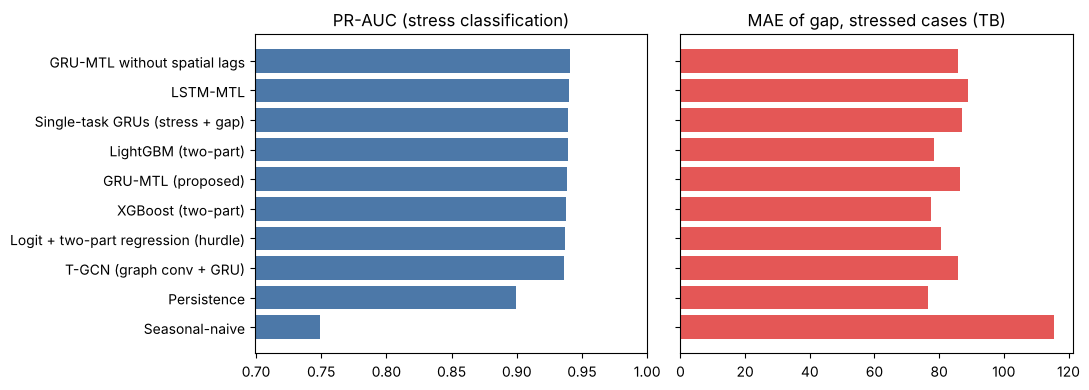

In [17]:
# Figure 4.7: two side-by-side horizontal bar charts (1 row, 2 panels, held in ax[0] and ax[1])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
r2 = res.sort_values('PR_AUC')                      # ascending: best model is drawn at the top
# Left panel: PR-AUC. The x-axis starts 0.05 below the lowest value so differences are visible.
ax[0].barh(r2.Model, r2.PR_AUC, color='#4c78a8'); ax[0].set_xlim(r2.PR_AUC.min() - 0.05, 1)
ax[0].set_title('PR-AUC (stress classification)')
# Right panel: gap error on the actually stressed test cases (shorter bar = better)
ax[1].barh(r2.Model, r2.MAE_stressed_TB, color='#e45756'); ax[1].set_title('MAE of gap, stressed cases (TB)')
ax[1].set_yticklabels([])                           # model names are already on the left panel
# tight_layout avoids overlapping labels; save_figure writes Outputs/figures/F4.07_...png
plt.tight_layout(); save_figure('4.07', 'model_comparison'); plt.show()

**How to read Figure 4.7.** The left panel shows PR-AUC (longer bar = better) with the best model at the top. Its axis does not start at 0, so small differences look larger than they are; read the exact values from Table 4.16. The right panel shows the gap error on actually stressed cases in TB, where a shorter bar is better. The models are in the same order in both panels, so a model near the top on the left with a long bar on the right is better at spotting stress than at sizing the shortfall.

## Step 10: Hypothesis Tests
Table 4.16 shows small differences between models. This step asks whether those differences are **statistically significant**, that is, larger than the chance variation one would expect from four test quarters. All tests are paired: both models are scored on exactly the same test cases.

**Reading a p-value.** A p-value is the probability of seeing a difference at least as large as the observed one if, in truth, the two models were equally good. A p-value below 0.05 is called significant at the 5% level; a larger p-value means the data cannot tell the two models apart.

### H1 and H2: Is the difference in discrimination significant?
- **DeLong test** for paired ROC-AUC differences (DeLong et al., 1988).
- **Sub-county cluster bootstrap** (1,000 resamples of sub-counties): 95% CI for the ROC-AUC and PR-AUC differences. Repeated quarters of the same sub-county are not independent, and resampling whole sub-counties accounts for that. The two tests can disagree; the column *Cluster CI excludes 0* shows where. The hypothesis verdicts in Notebook 05 require both: DeLong p < 0.05 **and** a cluster CI that excludes 0.
- For H2 the table adds one comparison that does not involve the proposed model: **T-GCN against GRU-MTL without spatial lags**. Both see the same non-spatial inputs, so the difference isolates what graph convolution adds.
- **Diebold–Mariano test** (panel form, standard errors clustered by sub-county) on the absolute errors of the expected gap.

**What each test does**
- **DeLong test** (function `delong`, with the helper `_midrank` for ranks with ties). Two ROC-AUCs measured on the same cases are correlated, so a test that treated them as independent would be misleading. DeLong et al. derived the variance of the AUC difference from each case's placement among the cases of the other class. The difference divided by its standard error is a z-statistic, and the p-value comes from the standard normal distribution.
- **Cluster bootstrap** (function `cluster_boot`). The bootstrap measures uncertainty by resampling the data many times and recomputing the statistic each time. Here whole sub-counties are drawn with replacement (a **cluster** bootstrap), so the four test quarters of a sub-county always stay together. The 2.5th and 97.5th percentiles of the 1,000 recomputed differences form the 95% confidence interval.
- **Diebold–Mariano (DM) test** (function `dm_panel`). A standard test of whether two forecasts are equally accurate. For each test case it takes the **loss differential** $d = |e_1| - |e_2|$, the absolute error of the first model minus that of the second. If the two models are equally accurate, the mean of $d$ is 0. The panel form estimates this mean by regressing $d$ on a constant, with standard errors clustered by sub-county.

`compare(a, b)` runs all three tests for one pair of models and returns one row of Table 4.18.

In [18]:
# _midrank ranks the values of x (1 = smallest); tied values share the average of their ranks.
# The leading underscore marks it as a small internal helper.
def _midrank(x):
    # J = positions that would sort x; Z = the sorted values; Tm will hold the ranks
    J = np.argsort(x); Z = x[J]; n = len(x); Tm = np.zeros(n); i = 0
    while i < n:
        j = i
        while j < n and Z[j] == Z[i]:               # find the run of values tied with Z[i]
            j += 1
        Tm[i:j] = 0.5 * (i + j - 1) + 1             # average rank of the run (ranks from 1)
        i = j
    out = np.empty(n); out[J] = Tm                  # put the ranks back in the original order
    return out

# DeLong test for two correlated ROC-AUCs (both models scored on the same cases), using the
# fast rank-based algorithm. Returns (AUC of p1 minus AUC of p2, two-sided p-value).
def delong(y, p1, p2):
    # Reorder the cases: the m stressed cases (y = 1) first, then the n non-stressed ones
    order = np.argsort(-y); m = int(y.sum()); n = len(y) - m
    P = np.vstack([p1, p2])[:, order]               # 2 rows: one per model
    # Midranks among stressed cases (tx), among non-stressed cases (ty) and among all (tz)
    tx = np.array([_midrank(p[:m]) for p in P]); ty = np.array([_midrank(p[m:]) for p in P]); tz = np.array([_midrank(p) for p in P])
    # AUC from ranks (Mann-Whitney form): the chance that a random stressed case is scored
    # above a random non-stressed case
    aucs = tz[:, :m].sum(1) / m / n - (m + 1) / (2 * n)
    # Placement values: for each stressed case, the share of non-stressed cases it outranks
    # (v01); for each non-stressed case, the share of stressed cases that outrank it (v10)
    v01 = (tz[:, :m] - tx) / n; v10 = 1 - (tz[:, m:] - ty) / m
    # 2 x 2 covariance matrix of the two AUC estimates (np.cov treats each row as one variable)
    S = np.cov(v01) / m + np.cov(v10) / n
    # z statistic: AUC difference / its standard error. Var(A - B) = Var A + Var B
    # - 2 Cov(A, B); the covariance term accounts for both models scoring the same cases.
    z = (aucs[0] - aucs[1]) / np.sqrt(S[0, 0] + S[1, 1] - 2 * S[0, 1])
    # Two-sided p-value: stats.norm.sf is the upper tail of the standard normal (1 - CDF)
    return aucs[0] - aucs[1], 2 * stats.norm.sf(abs(z))

# Sub-county of every test row: the "cluster" that the bootstrap resamples as a whole
unit_test = ii[test_idx]
# Cluster bootstrap: 95% percentile intervals for the ROC-AUC and PR-AUC differences
def cluster_boot(y, p1, p2, B=1000, seed=42):
    # default_rng(seed) is numpy's seeded random generator; uu = the distinct sub-counties
    rng = np.random.default_rng(seed); uu = np.unique(unit_test)
    # Dictionary: sub-county -> positions of its rows in the test arrays (its test quarters)
    rows_by_u = {u: np.where(unit_test == u)[0] for u in uu}
    d_roc, d_pr = [], []
    for _ in range(B):                              # B = 1000 resamples (_ = unused counter)
        # Draw as many sub-counties as there are, WITH replacement (some appear twice, some
        # not at all), and take all test rows of every drawn sub-county
        s = np.concatenate([rows_by_u[u] for u in rng.choice(uu, len(uu), replace=True)])
        if y[s].min() == y[s].max():                # only one class drawn: AUC undefined, skip
            continue
        d_roc.append(roc_auc_score(y[s], p1[s]) - roc_auc_score(y[s], p2[s]))
        d_pr.append(average_precision_score(y[s], p1[s]) - average_precision_score(y[s], p2[s]))
    # The 2.5th and 97.5th percentiles of the resampled differences = 95% interval
    return np.percentile(d_roc, [2.5, 97.5]), np.percentile(d_pr, [2.5, 97.5])

# Panel Diebold-Mariano test on absolute errors
def dm_panel(e1, e2):
    # Loss differential per test row (negative: model 1 was closer to the truth)
    d = np.abs(e1) - np.abs(e2)
    # Regressing d on a constant (a column of ones) estimates its mean, the MAE difference.
    # cov_type='cluster' computes the standard error with sub-counties as clusters, because the
    # test quarters of one sub-county are not independent.
    fit = sm.OLS(d, np.ones(len(d))).fit(cov_type='cluster', cov_kwds={'groups': unit_test})
    return fit.params[0], fit.pvalues[0]            # mean difference, p-value (H0: mean = 0)

ref = 'GRU-MTL (proposed)'                          # the reference model in most comparisons
yt = y_c[test_idx]; gt = y_g[test_idx]              # observed stress (0/1) and gap (TB)

# Run all three tests for model a against model b and return one row of Table 4.18.
# preds[name] (filled by record()) holds each model's test probability 'p' and expected gap
# 'g_exp'. For persistence and seasonal-naive 'p' is a score rather than a probability; AUCs
# only use the ranking of the scores, so the tests still apply.
def compare(a, b):
    d_auc, p_dl = delong(yt, preds[a]['p'], preds[b]['p'])
    ci_roc, ci_pr = cluster_boot(yt, preds[a]['p'], preds[b]['p'])
    # Errors = observed gap minus each model's expected gap
    d_mae, p_dm = dm_panel(gt - preds[a]['g_exp'], gt - preds[b]['g_exp'])
    return {'Comparison': f'{a} vs {b}', 'ΔROC-AUC': d_auc, 'DeLong p': p_dl,
            'ΔROC CI low': ci_roc[0], 'ΔROC CI high': ci_roc[1],
            'ΔPR-AUC CI low': ci_pr[0], 'ΔPR-AUC CI high': ci_pr[1],
            # True when the ROC-AUC interval lies wholly above 0 or wholly below 0
            'Cluster CI excludes 0': bool(ci_roc[0] > 0 or ci_roc[1] < 0),
            'ΔMAE expected gap (TB)': d_mae, 'DM p': p_dm}

# GRU-MTL against every other model in Table 4.16 (a list comprehension is a compact for-loop)
tests = [compare(ref, other) for other in res.Model if other != ref]
tests.append(compare('T-GCN (graph conv + GRU)', 'GRU-MTL without spatial lags'))   # H2: graph convolution alone
tests = pd.DataFrame(tests)
print("Table 4.18: Pairwise tests (GRU-MTL against every other model; T-GCN against GRU-MTL without spatial lags for H2), test quarters")
display(save_table(tests.round(4), '4.18', 'hypothesis_tests'))

Table 4.18: Pairwise tests (GRU-MTL against every other model; T-GCN against GRU-MTL without spatial lags for H2), test quarters
[saved] Outputs/tables/T4.18_hypothesis_tests.csv


,Comparison,ΔROC-AUC,DeLong p,ΔROC CI low,ΔROC CI high,ΔPR-AUC CI low,ΔPR-AUC CI high,Cluster CI excludes 0,ΔMAE expected gap (TB),DM p
0,GRU-MTL (proposed) vs GRU-MTL without spatial ...,0.0002,0.7420,-0.0010,0.0018,-0.0054,0.0010,False,0.4139,0.2172
1,GRU-MTL (proposed) vs LSTM-MTL,0.0000,0.9927,-0.0010,0.0010,-0.0049,0.0027,False,-0.3921,0.0163
2,GRU-MTL (proposed) vs Single-task GRUs (stress...,0.0000,0.9005,-0.0006,0.0007,-0.0027,0.0022,False,0.0869,0.7680
3,GRU-MTL (proposed) vs LightGBM (two-part),0.0010,0.5538,-0.0024,0.0045,-0.0101,0.0102,False,0.7827,0.4750
4,GRU-MTL (proposed) vs XGBoost (two-part),0.0017,0.2062,-0.0009,0.0051,-0.0064,0.0105,False,0.8666,0.2888
5,GRU-MTL (proposed) vs Logit + two-part regress...,0.0025,0.1395,-0.0005,0.0062,-0.0073,0.0136,False,-1.8941,0.2357
6,GRU-MTL (proposed) vs T-GCN (graph conv + GRU),0.0017,0.0295,0.0002,0.0035,-0.0027,0.0074,True,0.3202,0.4407
7,GRU-MTL (proposed) vs Persistence,0.0272,0.0008,0.0123,0.0458,0.0167,0.0685,True,1.9323,0.2127
8,GRU-MTL (proposed) vs Seasonal-naive,0.1203,0.0000,0.0720,0.1740,0.1241,0.2643,True,-19.0974,0.0343
9,T-GCN (graph conv + GRU) vs GRU-MTL without sp...,-0.0015,0.0331,-0.0031,-0.0001,-0.0096,-0.0003,True,0.0937,0.6828


Reading the table: a **positive** ΔROC-AUC favours the first model of the comparison (GRU-MTL in every row except the last), and a **negative** ΔMAE means the first model has smaller gap errors. A confidence interval that contains 0, or a p-value ≥ 0.05, means the difference is not statistically significant.

**Column by column (Table 4.18)**
- `ΔROC-AUC` and `DeLong p`: the ROC-AUC of the first model minus that of the second, and the DeLong p-value for that difference.
- `ΔROC CI low` / `ΔROC CI high` and `ΔPR-AUC CI low` / `ΔPR-AUC CI high`: the 95% cluster-bootstrap intervals for the two differences. An interval entirely above 0 favours the first model, one entirely below 0 favours the second, and one that straddles 0 is inconclusive.
- `Cluster CI excludes 0`: True when the **ROC-AUC** interval lies wholly on one side of 0.
- `ΔMAE expected gap (TB)` and `DM p`: the mean difference in absolute expected-gap error (first model minus second) and its Diebold–Mariano p-value.

**Applying the study's rule.** A difference in discrimination counts as significant only if `DeLong p` < 0.05 **and** `Cluster CI excludes 0` is True. For H1, look at the rows comparing GRU-MTL with the single-task GRUs and with XGBoost. For H2, look at the row against GRU-MTL without spatial lags (do spatial-lag features help?) and at the last row (does graph convolution help?). The table holds ten comparisons, so a single p-value just below 0.05 should be read with some caution.

### H3: Residual spatial autocorrelation (Moran's I on GRU-MTL test residuals)
Both tasks are tested: the stress residual (observed stress minus predicted probability) and the gap residual (observed gap minus expected gap, TB).

**What residual Moran's I means.** A residual is what the model got wrong for one sub-county in one quarter. Moran's I measures whether neighbouring sub-counties (the 5 nearest, weight matrix `W_knn` from Step 1) have similar residuals. A value near 0 means the errors are scattered randomly over the map; a clearly positive value means errors cluster in space, for example the model under-predicting a whole region at once. H3 states that after modelling the residuals show no significant spatial autocorrelation. Clustered residuals would mean the model still misses some spatial structure.

**How the code does it.** For each of the four test quarters, the residuals of that quarter form one map, and `morans_i` (project_config.py) computes I and a **permutation p-value**: the residuals are shuffled randomly across sub-counties 999 times, and the p-value is the share of shuffles that give an I at least as far from the shuffled average as the observed one. With 999 shuffles the smallest possible p-value is 0.001.

In [19]:
moran_res = []
# One Moran's I per test quarter, because each quarter is one map of residuals
for q in sorted(np.unique(tq[test_idx])):
    # Positions of quarter q inside the test arrays. They come in sub-county order, the same
    # order as the rows and columns of the weight matrix W_knn.
    rows_q = np.where(tq[test_idx] == q)[0]
    # Stress residual = observed 0/1 minus predicted probability; returns (I, permutation p)
    I, p = morans_i(yt[rows_q] - preds[ref]['p'][rows_q], W_knn)
    # Gap residual = observed gap minus expected gap (TB)
    Ig, pg = morans_i(gt[rows_q] - preds[ref]['g_exp'][rows_q], W_knn)
    moran_res.append({'target q_idx': q, 'Quarter': qlabels[q], "Moran's I (stress residual)": I, 'p stress (perm.)': p,
                      "Moran's I (gap residual)": Ig, 'p gap (perm.)': pg})
moran_res = pd.DataFrame(moran_res).round(4)
print("Table 4.19: Moran's I of GRU-MTL test residuals, stress and gap tasks")
display(save_table(moran_res, '4.19', 'residual_moran'))

Table 4.19: Moran's I of GRU-MTL test residuals, stress and gap tasks
[saved] Outputs/tables/T4.19_residual_moran.csv


,target q_idx,Quarter,Moran's I (stress residual),p stress (perm.),Moran's I (gap residual),p gap (perm.)
0,13,Q4_24_25,-0.0573,0.084,0.0115,0.452
1,14,Q1_25_26,0.0356,0.233,0.1196,0.001
2,15,Q2_25_26,-0.0082,0.847,0.0227,0.295
3,16,Q3_25_26,0.0080,0.751,0.0009,0.866


**How to read Table 4.19.** There is one row per test quarter. For each task, a p-value of 0.05 or more means no significant spatial clustering of errors in that quarter, which supports H3. A p-value below 0.05 together with a positive I means the errors cluster in space in that quarter; the summary at the end of this notebook states where this happens.

## Step 11: Where Does the Model Work? Strata and Spatial Generalisation
The proposal (Section 3.4.4) asks for performance by **infrastructure-density strata** and for **spatial generalisation through grouped county holdouts**.

A single overall score can hide groups where a model works poorly. **Strata** (singular *stratum*) are subgroups of the test cases defined by a characteristic known in advance. Scoring each stratum separately shows where the forecasts can be trusted most.

### 11.1 Performance by stratum (test quarters)
- **Recorded infrastructure:** terciles of the number of recorded sites in the sub-county (a proxy for urban versus rural density).
- **Data confidence:** whether the sub-county had at least 20 Ookla tests in the last observed quarter of the input window.

ROC-AUC and PR-AUC are not reported for a stratum with fewer than 10 stressed cases, because they would rest on a handful of events.

**How the code does it.** `pd.qcut` splits the sub-counties into three equal-sized groups (terciles) by their number of recorded sites. The data-confidence flag is taken at the forecast origin, the last quarter of each input window, so it is information that is available when the forecast is made. For every level of each stratum the code scores GRU-MTL, the XGBoost pair and persistence on the test rows in that level. The AUCs are also left out if a level has no non-stressed case. The line printed before the table gives the stress rate of each site tercile over the whole panel, which helps explain why the terciles behave differently.

In [20]:
# Recorded sites per sub-county. The site registry is a fixed snapshot, so the count is the
# same in every quarter and column 0 (the first quarter) is enough.
n_sites_unit = wide('n_sites')[:, 0]
# pd.qcut cuts at the 1/3 and 2/3 quantiles: three equal-sized groups (terciles)
site_tercile = pd.qcut(n_sites_unit, 3, labels=['Few sites (lowest third)', 'Middle third', 'Many sites (highest third)'])
# Low-confidence flag (< 20 Ookla tests) in the origin quarter tt of every sample
# (ii = sub-county, tt = last input quarter of each sample)
low_conf_origin = wide('low_confidence')[ii, tt]                # known when the forecast is made
# Stratum label of every test row, for each of the two ways of splitting the test set
strata = {'Recorded infrastructure': np.asarray(site_tercile)[ii[test_idx]],
          'Ookla data at forecast origin': np.where(low_conf_origin[test_idx] == 1, f'< {LOW_TESTS} tests', f'≥ {LOW_TESTS} tests')}
rows = []
for dim, lab in strata.items():
    for level in pd.unique(lab):                    # each group, e.g. 'Middle third'
        m = lab == level                            # True/False mask: test rows in this group
        # GRU-MTL against the XGBoost pair and the persistence benchmark
        for name in [ref, 'XGBoost (two-part)', 'Persistence']:
            p = preds[name]['p'][m]; yt_m = yt[m]
            # AUCs only with at least 10 stressed cases and at least one non-stressed case
            ok = 10 <= yt_m.sum() < len(yt_m)
            # np.nan = missing value, shown as NaN in the table
            rows.append({'Stratum': dim, 'Level': level, 'Model': name, 'n': int(m.sum()), 'Stressed cases': int(yt_m.sum()),
                         'ROC_AUC': roc_auc_score(yt_m, p) if ok else np.nan,
                         'PR_AUC': average_precision_score(yt_m, p) if ok else np.nan,
                         'MAE_expected_TB': np.mean(np.abs(gt[m] - preds[name]['g_exp'][m]))})
strata_tab = pd.DataFrame(rows).round(4)
# YC.mean(1) = share of the 17 quarters each sub-county was stressed; then average per tercile
panel_rate = pd.Series(YC.mean(1)).groupby(np.asarray(site_tercile)).mean()      # all 17 quarters, by unit tercile
print("Stress rate over the whole panel by recorded-site tercile: " + ", ".join(f"{k} {100 * v:.1f}%" for k, v in panel_rate.items()))
print("Table 4.20: Test performance by stratum")
display(save_table(strata_tab, '4.20', 'performance_by_stratum'))

Stress rate over the whole panel by recorded-site tercile: Few sites (lowest third) 41.7%, Many sites (highest third) 6.2%, Middle third 12.3%
Table 4.20: Test performance by stratum
[saved] Outputs/tables/T4.20_performance_by_stratum.csv


,Stratum,Level,Model,n,Stressed cases,ROC_AUC,PR_AUC,MAE_expected_TB
0,Recorded infrastructure,Many sites (highest third),GRU-MTL (proposed),392,1,NaN,NaN,3.7581
1,Recorded infrastructure,Many sites (highest third),XGBoost (two-part),392,1,NaN,NaN,4.3487
2,Recorded infrastructure,Many sites (highest third),Persistence,392,1,NaN,NaN,4.6410
3,Recorded infrastructure,Few sites (lowest third),GRU-MTL (proposed),392,198,0.9447,0.9522,43.3931
4,Recorded infrastructure,Few sites (lowest third),XGBoost (two-part),392,198,0.9422,0.9522,41.2022
5,Recorded infrastructure,Few sites (lowest third),Persistence,392,198,0.9134,0.9235,39.4765
6,Recorded infrastructure,Middle third,GRU-MTL (proposed),392,37,0.9881,0.8936,16.4435
7,Recorded infrastructure,Middle third,XGBoost (two-part),392,37,0.9881,0.8944,15.4440
8,Recorded infrastructure,Middle third,Persistence,392,37,0.9852,0.8831,13.6803
9,Ookla data at forecast origin,≥ 20 tests,GRU-MTL (proposed),647,91,0.9907,0.9463,24.8609


**How to read Table 4.20.** Each row is one model in one level of a stratum; `n` is the number of test rows in that level and `Stressed cases` the number of them that were stressed. NaN in the AUC columns means the level had fewer than 10 stressed cases. Compare the models **within** a level to see whether GRU-MTL keeps its advantage over persistence there. Be careful when comparing AUCs **across** levels: part of the overall discrimination comes from telling the strata apart (stress is far more common where few sites are recorded), so an AUC inside a single stratum can be lower than the overall AUC even for a good model. MAE_expected_TB is reported for every level and tends to be larger where stress, and therefore the gap, is more common.

### 11.2 Spatial generalisation: county holdout
The 47 counties are split into 5 groups. For each group, GRU-MTL (5 seeds) and the XGBoost pair are trained on the development quarters of the **other** counties only, and then forecast the test quarters of the held-out counties. Every test sub-county is therefore predicted by a model that never saw its county. If performance stays close to the standard evaluation, the models learned relationships that transfer to new places rather than memorising locations.

**Why a county holdout.** In the standard evaluation every sub-county appears in both training and test (in different quarters), so the model may partly rely on what it learned about that particular place. Holding out whole counties asks a harder question: does the model work for an area it has never seen? Whole counties are held out, rather than single sub-counties, because a held-out sub-county's close neighbours in the same county would otherwise still be in the training data.

**How the code does it.** `GroupKFold(n_splits=5)` from scikit-learn makes 5 folds in which all sub-counties of a county stay together (the county is the *group*), so each county is held out exactly once. In each fold, `tr` holds the development rows of the other counties and `te` the test rows of the held-out counties. GRU-MTL is retrained with the same settings and number of epochs as the main model, and the XGBoost pair with its tuned depth and number of trees. The predictions are stored in the dictionary `ho` until every test row has one, and are then scored next to the standard results.

In [21]:
from sklearn.model_selection import GroupKFold
# County of each sub-county, in the same order as units
county_unit = panel.groupby('subcounty')['county'].first().loc[units].values
test_units = ii[test_idx]                           # sub-county of each test row
# Holdout predictions for every test row, filled in fold by fold (np.zeros = placeholders)
ho = {k: np.zeros(len(test_idx)) for k in ['p_gru', 'g_gru', 'p_xgb', 'g_xgb']}
t0 = time.time()
# GroupKFold splits the N sub-counties into 5 folds, keeping each county's sub-counties in the
# same fold. Each loop gives (training part, held-out part); the training part is unused (_)
for _, held_units in GroupKFold(n_splits=5).split(np.arange(N), groups=county_unit):
    # ~ means "not": rows of sub-counties outside the held-out counties
    tr = np.where(~np.isin(ii, held_units) & (tq <= TRAIN_MAX_Q))[0]    # development quarters, other counties only
    # Positions in the test arrays of the held-out sub-counties, and their sample row numbers
    pos_in_test = np.where(np.isin(test_units, held_units))[0]
    te = test_idx[pos_in_test]
    # GRU-MTL, one run per seed, same settings and epochs as the main model; predict te
    outs = [train_net(SPECS[ref], tr, epochs=EPOCHS[ref], seed=s)['predict'](te) for s in SEEDS]
    # Seed ensemble: average the probabilities (o[0]) and gaps (o[1]) across the 5 seeds
    ho['p_gru'][pos_in_test] = np.mean([o[0] for o in outs], 0)
    ho['g_gru'][pos_in_test] = np.mean([o[1] for o in outs], 0)
    # XGBoost pair (Step 7) refitted on the same rows with the tuned depth and number of trees
    clf, reg = fit_xgb_pair(tr, XGB_DEPTH, XGB_N)
    # predict_proba gives one column per class; [:, 1] = probability of being stressed
    ho['p_xgb'][pos_in_test] = clf.predict_proba(tab.iloc[te])[:, 1]
    # Regressor predicts ln(1+gap); expm1 converts back to TB and clip floors it at 0
    ho['g_xgb'][pos_in_test] = np.clip(np.expm1(reg.predict(tab.iloc[te])), 0, None)
print(f"County-holdout refits done ({time.time() - t0:.0f}s)")

pos = yt == 1                                       # stressed test rows
rows = []
# Score four combinations: 2 models x (standard evaluation, county held out)
for name, evaluation, p, g_cond in [
        (ref, 'Standard (all counties in training)', preds[ref]['p'], preds[ref]['g_cond']),
        (ref, 'County held out', ho['p_gru'], ho['g_gru']),
        ('XGBoost (two-part)', 'Standard (all counties in training)', preds['XGBoost (two-part)']['p'], preds['XGBoost (two-part)']['g_cond']),
        ('XGBoost (two-part)', 'County held out', ho['p_xgb'], ho['g_xgb'])]:
    # Same metrics as Table 4.16: AUCs, gap error on stressed cases, expected-gap error p * g
    rows.append({'Model': name, 'Evaluation': evaluation,
                 'ROC_AUC': roc_auc_score(yt, p), 'PR_AUC': average_precision_score(yt, p),
                 'MAE_stressed_TB': np.mean(np.abs(gt[pos] - g_cond[pos])), 'MAE_expected_TB': np.mean(np.abs(gt - p * g_cond))})
holdout_tab = pd.DataFrame(rows).round(4)
print("Table 4.21: Spatial generalisation, standard evaluation vs county holdout (test quarters)")
display(save_table(holdout_tab, '4.21', 'county_holdout'))

County-holdout refits done (56s)
Table 4.21: Spatial generalisation, standard evaluation vs county holdout (test quarters)
[saved] Outputs/tables/T4.21_county_holdout.csv


,Model,Evaluation,ROC_AUC,PR_AUC,MAE_stressed_TB,MAE_expected_TB
0,GRU-MTL (proposed),Standard (all counties in training),0.9824,0.9389,86.5952,21.1983
1,GRU-MTL (proposed),County held out,0.9813,0.9346,91.8071,21.7840
2,XGBoost (two-part),Standard (all counties in training),0.9807,0.9375,77.6330,20.3316
3,XGBoost (two-part),County held out,0.9810,0.9369,81.3208,20.4811


**How to read Table 4.21.** For each model, compare the *County held out* row with the *Standard* row. A small drop in ROC-AUC and PR-AUC (or a small rise in the MAEs) means the model transfers well to places it has never seen; a large drop would mean it had learned location-specific patterns. Some drop is expected even with good transfer, because each holdout model is trained on only about four-fifths of the sub-counties.

## Step 12: Uncertainty
A point forecast ("the gap will be X TB") says nothing about how sure the model is. This step adds two kinds of uncertainty information: **prediction intervals** for the size of the gap, and a check of whether the **stress probabilities** can be taken at face value.

### 12.1 Split-conformal 90% prediction intervals for the load gap (GRU-MTL)
A GRU-MTL trained on target quarters ≤ 10 is **calibrated** on quarters 11–12, giving the 90% quantile $\hat q$ of absolute log-gap errors on stressed cases. Test intervals are $[\exp(\hat r - \hat q) - 1,\ \exp(\hat r + \hat q) - 1]$, which target 90% coverage of stressed cases.

Split-conformal coverage is guaranteed only when calibration and test errors are exchangeable. Here the calibration quarters lie 1–2 quarters after the training window and the test quarters 3–6 quarters after it, so under the upward trend the test errors can be larger and coverage can fall below 90%. Table 4.22 reports the empirical coverage. The intervals describe this separately trained model (targets ≤ 10), not the model in Table 4.16 or the forecast model.

**Key terms**
- **Conformal prediction** turns any point forecast into an interval without assuming a distribution for the errors. It looks at how large the model's errors were on a **calibration set** (data not used for training) and makes the interval just wide enough to have covered 90% of those errors. *Split* conformal means that training and calibration use separate data, here separate quarters.
- **Coverage** is the share of actual values that fall inside their intervals. A 90% interval should contain the true gap about 90% of the time.
- **Exchangeable** errors behave as if they came from the same distribution in any order; this is the assumption behind the coverage guarantee.

**How the code does it.** Five GRU-MTL seeds are trained on target quarters ≤ 10 (`cal_tr`), and their averaged log-gap prediction $\hat r$ is computed by `ens_logr`. On the stressed calibration cases (`cal_pos`) the absolute errors $|\ln(1+\text{gap}) - \hat r|$ are the **scores**, and `q_hat` is their quantile at level $\lceil (n+1) \times 0.9 \rceil / n$. This level is slightly above 0.9, a small-sample correction that is part of the conformal method. Each stressed test case then gets the interval $\hat r \pm \hat q$ on the log scale, converted back to TB; the lower end is cut at 0 because a gap cannot be negative. Because the interval is symmetric on the log scale, it is wider above the point forecast than below it once converted to TB.

In [22]:
# Three separate sets: train on target quarters <= 10, calibrate on 11-12, test on 13-16
cal_tr = np.where(tq <= 10)[0]; cal = np.where(np.isin(tq, (11, 12)))[0]
# GRU-MTL with the main model's settings and epochs, one run per seed
cal_runs = [train_net(SPECS[ref], cal_tr, epochs=EPOCHS[ref], seed=s) for s in SEEDS]
# Seed-averaged gap prediction on the ln(1+gap) scale (item [2] returned by predict)
def ens_logr(idx):
    return np.mean([r['predict'](idx)[2] for r in cal_runs], axis=0)
cal_pos = cal[y_c[cal] == 1]                        # stressed calibration cases only
# Conformity scores: absolute errors on the log scale
scores = np.abs(log_g[cal_pos] - ens_logr(cal_pos))
n_cal = len(scores)
# Conformal quantile at level ceil((n+1) x 0.9) / n, slightly above 0.9 (finite-sample
# correction); min(1, ...) keeps the level from exceeding 1
q_hat = np.quantile(scores, min(1, np.ceil((n_cal + 1) * 0.9) / n_cal))
test_pos = test_idx[y_c[test_idx] == 1]             # stressed test cases
centre = ens_logr(test_pos)                          # predicted ln(1+gap) = interval centre
# Interval centre -/+ q_hat on the log scale; expm1 converts to TB; lower end floored at 0
lo, hi = np.expm1(centre - q_hat).clip(0), np.expm1(centre + q_hat)
# Empirical coverage: share of observed test gaps inside their interval (True counts as 1)
coverage = np.mean((y_g[test_pos] >= lo) & (y_g[test_pos] <= hi))
conformal = pd.DataFrame([{'Calibration cases': n_cal, 'q_hat (log scale)': q_hat, 'Target coverage': 0.90,
                           'Empirical test coverage': coverage, 'Median interval width (TB)': np.median(hi - lo)}]).round(4)
print("Table 4.22: Split-conformal 90% intervals for the load gap (GRU-MTL trained on target quarters ≤ 10)")
display(save_table(conformal, '4.22', 'conformal'))

Table 4.22: Split-conformal 90% intervals for the load gap (GRU-MTL trained on target quarters ≤ 10)
[saved] Outputs/tables/T4.22_conformal.csv


,Calibration cases,q_hat (log scale),Target coverage,Empirical test coverage,Median interval width (TB)
0,118,1.454,0.9,0.9025,282.2


**How to read Table 4.22.** `Calibration cases` is the number of stressed calibration cases the quantile is based on. `q_hat (log scale)` is the half-width of every interval on the $\ln(1+\text{gap})$ scale. In TB it works as a multiplier: with $\hat g$ the point forecast of the gap, the interval runs from $(1+\hat g)\,e^{-\hat q} - 1$ to $(1+\hat g)\,e^{\hat q} - 1$. An `Empirical test coverage` close to the 0.90 target means the intervals are honest; a value clearly below 0.90 means they are too narrow for the test quarters. `Median interval width (TB)` shows how informative the intervals are: honest but very wide intervals say that the size of a sub-county's gap is hard to pin down.

### 12.2 Probability calibration (reliability diagram)
A model is **well calibrated** if its probabilities mean what they say: among all cases given a stress probability of about 0.3, about 30% should turn out to be stressed. A model can rank cases well (high ROC-AUC) and still be poorly calibrated, for example if all its probabilities are too high. Calibration matters here because Notebook 05 uses the stress probability itself when it builds the Network Deficit Score (NDS).

A **reliability diagram** checks this. The test predictions are grouped into 10 bins of width 0.1 (0–0.1, 0.1–0.2, and so on). For every bin with at least 10 cases, the mean predicted probability (x-axis) is plotted against the share of those cases that were actually stressed (y-axis). The diagram compares GRU-MTL with the XGBoost pair and the logit hurdle model, and the legend gives each model's Brier score.

[saved] Outputs/figures/F4.08_calibration.png


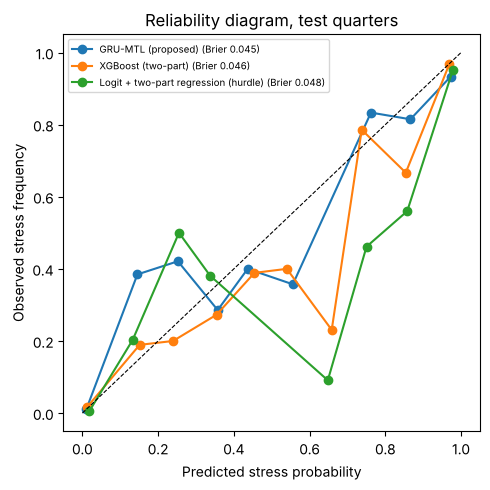

In [23]:
fig, ax = plt.subplots(figsize=(5, 5))
bins = np.linspace(0, 1, 11)                        # 11 edges 0, 0.1, ..., 1 -> 10 bins
for name in [ref, 'XGBoost (two-part)', 'Logit + two-part regression (hurdle)']:
    # np.digitize with the 9 inner edges gives each probability a bin number from 0 to 9
    p = preds[name]['p']; b = np.digitize(p, bins[1:-1])
    # Per bin with >= 10 cases: mean predicted probability (x) and observed stress rate (y)
    xs = [p[b == k].mean() for k in range(10) if (b == k).sum() >= 10]
    ys = [yt[b == k].mean() for k in range(10) if (b == k).sum() >= 10]
    # One line of dots per model; the legend label includes its Brier score
    ax.plot(xs, ys, 'o-', label=f"{name} (Brier {brier_score_loss(yt, p):.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)              # dashed diagonal = perfect calibration
ax.set_xlabel('Predicted stress probability'); ax.set_ylabel('Observed stress frequency')
ax.set_title('Reliability diagram, test quarters'); ax.legend(fontsize=7)
plt.tight_layout(); save_figure('4.08', 'calibration'); plt.show()

**How to read Figure 4.8.** The dashed diagonal is perfect calibration. Points **below** the line mean the model predicts more stress than actually happens in that probability range (over-forecasting); points **above** it mean it predicts too little. A bin with few cases gives a noisy point, which is why bins with fewer than 10 cases are left out. A lower Brier score in the legend means more accurate probabilities overall.

## Step 13: Refit on All Quarters and Forecast Q4 2025/26
For the prescriptive stage, GRU-MTL (5 seeds) and the XGBoost pair are refitted on **all** target quarters (4–16), and the windows ending in the last observed quarter (Q3 2025/26) forecast the next, unobserved quarter. Models, scalers and forecasts are saved for Notebook 05.

**Why refit.** To **refit** a model is to train it again, with exactly the same settings, on more data. The test quarters were held back only to measure accuracy honestly. That has now been done, so the final forecasting model may learn from them too, and they are the most recent quarters. No setting is re-chosen here: the hidden size, λ, number of epochs and XGBoost settings are the ones selected earlier on the development quarters. The refitted model has no test set of its own, so the accuracy measured in Steps 9–12 is the best available guide to how well it forecasts.

**How the code does it**
- `final_runs`: five GRU-MTL runs (one per seed) trained on every sample, keeping the trained networks and their scalers (`return_model=True`).
- `seq_next`: the last 4 observed quarters of every sub-county, which form the input window for forecasting Q4 2025/26. `predict_next` scales it with each run's own scalers and returns the stress probability and gap for every sub-county. `P_next` and `G_next` hold the forecasts of the 5 seeds.
- `tab_next`: the same window in the flat (tabular) layout used by XGBoost, built exactly like `tab` in Step 3. The XGBoost pair is refitted on all samples with `fit_xgb_pair`.
- `forecast`: one row per sub-county with the forecasts and the current situation. The ten sub-counties with the highest stress probability are displayed.

**Columns of the forecast table**
- `breach_prob`: the GRU-MTL stress probability for Q4 2025/26, averaged over the 5 seeds; `breach_prob_sd_seeds` is its standard deviation across the seeds (a small value means the seeds agree).
- `pred_gap_TB`: the predicted gap if the sub-county is stressed; `expected_gap_TB`: probability × gap, averaged over the seeds.
- `xgb_breach_prob`: the XGBoost stress probability, an independent cross-check.
- `current_stress`, `current_gap_TB`: the observed state in the last observed quarter (Q3 2025/26).
- `devices_last2q`, `tests_last2q`: the average number of Ookla devices and tests over the last two quarters, a measure of how much measured demand data there is.
- `low_confidence` (fewer than 20 Ookla tests), `sparse_infrastructure` (fewer than 5 recorded sites), `n_sites`, `n_LTE`, `capacity_units`: data-quality flags and recorded infrastructure in the last quarter.

In [24]:
all_idx = np.arange(len(tq))                        # every sample: target quarters 4-16
# Refit GRU-MTL on all samples, one run per seed, with the epochs chosen earlier; keep the
# trained networks and their scalers (return_model=True)
final_runs = [train_net(SPECS[ref], all_idx, epochs=EPOCHS[ref], seed=s, return_model=True) for s in SEEDS]

# Windows ending at the last observed quarter t = T-1 (forecast target T, i.e. Q4 2025/26)
seq_next = Xd_full[:, T - L:T, :]                                  # (N, L, F)
# Forecast every sub-county with one trained run, scaling the inputs with that run's scalers
def predict_next(run):
    m, sc = run['model'], run['scalers']; cols = sc['dyn_cols']; F = len(cols)
    # Scale the dynamic inputs exactly as in training and reshape back to (N, L, F)
    xd = torch.tensor(sc['dyn'].transform(seq_next[:, :, cols].reshape(-1, F)).reshape(N, L, F), dtype=torch.float32)
    # Scale the static covariates the same way
    xs = torch.tensor(sc['stat'].transform(Xs_unit), dtype=torch.float32)
    m.eval()                                        # evaluation mode: dropout off
    with torch.no_grad():
        c, r = m(xd, xs)
    # Probability (sigmoid of the score) and gap in TB (undo standardisation and log, min 0)
    return 1 / (1 + np.exp(-c.numpy())), np.clip(np.expm1(r.numpy() * sc['gsd'] + sc['gmu']), 0, None)

nx = [predict_next(r) for r in final_runs]          # one (probability, gap) pair per seed
# Arrays of shape (5 seeds, N sub-counties)
P_next = np.array([a for a, _ in nx]); G_next = np.array([b for _, b in nx])

# Tabular features for XGBoost, built like tab in Step 3: the last quarter's dynamic features,
# three lags of rel_ratio (dynamic column 0) and the static covariates
tab_next = pd.DataFrame(seq_next[:, -1, :], columns=ALL_DYN)
for k in [1, 2, 3]:
    tab_next[f'rel_ratio_lag{k}'] = seq_next[:, -1 - k, 0]
for j, c in enumerate(STAT):
    tab_next[c] = Xs_unit[:, j]
# XGBoost pair refitted on all samples with the tuned settings
xgb_clf_all, xgb_reg_all = fit_xgb_pair(all_idx, XGB_DEPTH, XGB_N)

# Panel rows of the last observed quarter (T-1), in the same sub-county order as units
last = panel[panel.q_idx == T - 1].set_index('subcounty').loc[units]
# One row per sub-county; .mean(0) and .std(0) summarise across the 5 seeds (axis 0)
forecast = pd.DataFrame({
    'subcounty': units, 'county': last['county'].values, 'lat': last['lat'].values, 'lon': last['lon'].values,
    'forecast_quarter': 'Q4_25_26',
    # GRU-MTL stress probability: seed mean and seed-to-seed spread
    'breach_prob': P_next.mean(0), 'breach_prob_sd_seeds': P_next.std(0),
    # Gap if stressed, and expected gap (probability x gap for each seed, then averaged)
    'pred_gap_TB': G_next.mean(0), 'expected_gap_TB': (P_next * G_next).mean(0),
    # XGBoost cross-check; tab_next[TAB] puts the columns in the order used in training
    'xgb_breach_prob': xgb_clf_all.predict_proba(tab_next[TAB])[:, 1],
    # Current state in the last observed quarter (gap converted from GB to TB)
    'current_stress': last['capacity_breach_target'].values, 'current_gap_TB': last['traffic_deficit_GB'].values / 1000,
    # Average Ookla devices and tests over the last two quarters (q_idx T-2 and T-1)
    'devices_last2q': panel[panel.q_idx >= T - 2].groupby('subcounty')['devices'].mean().loc[units].values,
    'tests_last2q': panel[panel.q_idx >= T - 2].groupby('subcounty')['tests'].mean().loc[units].values,
    # Data-quality flags and recorded infrastructure in the last quarter
    'low_confidence': last['low_confidence'].values, 'sparse_infrastructure': last['sparse_infrastructure'].values,
    'n_sites': last['n_sites'].values,
    'n_LTE': last['n_LTE'].values, 'capacity_units': last['capacity_units'].values,
})
# The ten sub-counties with the highest forecast stress probability
display(forecast.sort_values('breach_prob', ascending=False).head(10).round(3))

,subcounty,county,lat,lon,forecast_quarter,breach_prob,breach_prob_sd_seeds,pred_gap_TB,expected_gap_TB,xgb_breach_prob,current_stress,current_gap_TB,devices_last2q,tests_last2q,low_confidence,sparse_infrastructure,n_sites,n_LTE,capacity_units
232,Pokot South Sub County,WEST POKOT,1.420,35.273,Q4_25_26,1.000,0.000,227.771,227.715,0.990,1,241.775,3.0,11.0,1,1,3,0,0.3
137,LAMU EAST,LAMU,-2.057,41.104,Q4_25_26,1.000,0.000,187.915,187.835,0.989,1,128.767,2.5,5.0,1,1,3,0,0.4
61,Ijara Sub County,GARISSA,-1.683,40.198,Q4_25_26,0.999,0.000,161.281,161.176,0.989,1,122.178,3.0,5.0,1,1,3,0,0.3
183,Merti Sub County,ISIOLO,1.066,38.667,Q4_25_26,0.999,0.000,67.788,67.742,0.988,1,67.813,1.5,3.0,1,1,1,0,0.1
155,MANDERA SOUTH,MANDERA,2.812,40.932,Q4_25_26,0.999,0.000,339.034,338.819,0.993,1,381.736,8.0,27.0,1,1,2,0,1.1
189,Mt Elgon Sub County,Bungoma,0.845,34.700,Q4_25_26,0.999,0.000,102.909,102.785,0.990,1,60.172,1.5,3.5,1,1,1,0,0.5
156,MANDERA WEST,MANDERA,3.395,40.223,Q4_25_26,0.999,0.000,57.914,57.843,0.986,1,44.159,0.5,0.5,1,1,1,0,0.1
6,Balambala Sub County,GARISSA,-0.068,39.125,Q4_25_26,0.998,0.001,48.056,47.983,0.976,1,36.556,1.0,3.0,1,1,2,0,0.2
82,Kangundo Sub County,Machakos,-1.352,37.348,Q4_25_26,0.998,0.000,233.216,232.833,0.996,1,267.329,6.0,12.0,1,0,12,0,2.2
220,Nyamira North Sub County,Nyamira,-0.504,35.008,Q4_25_26,0.998,0.000,302.391,301.849,0.994,1,348.823,9.5,21.0,0,0,9,0,3.0


**How to read this output.** The table lists the ten sub-counties with the highest forecast stress probability for Q4 2025/26. That quarter has not been observed yet, so these forecasts cannot be scored here. Useful checks are whether GRU-MTL (`breach_prob`) and XGBoost (`xgb_breach_prob`) agree, whether the sub-county is already stressed now (`current_stress` = 1), and the data-quality flags: a high forecast for a sub-county flagged `low_confidence` rests on few Ookla tests and should be treated with more care. Notebook 05 combines these forecasts into the NDS ranking.

### Save artefacts for Notebook 05
Notebook 05 explains the forecasts and ranks the sub-counties without retraining anything, so the models and data it needs are written to `Outputs/models/`:

| File | Contents |
|---|---|
| `forecast_next_quarter.parquet` | The forecast table above, one row per sub-county |
| `test_predictions.parquet` | Every model's test-quarter stress probability (`p__<model>`) and expected gap (`gexp__<model>`), next to the observed values |
| `gru_mtl_final_seed0.pth` to `gru_mtl_final_seed4.pth` | Weights of the five final GRU-MTL networks (the network structure is rebuilt from project_config.py) |
| `gru_mtl_final_scalers.pkl` | The scalers of each of those five networks |
| `xgb_clf_final.json`, `xgb_reg_final.json` | The refitted XGBoost classifier and regressor |
| `arrays_next.npz` | The input arrays (forecast window, static covariates, all samples, labels) and the neighbour list |
| `config.json` | Feature lists and the selected settings (hidden size, λ, epochs, XGBoost depth and trees, seeds, number of neighbours) |

In [25]:
# Next-quarter forecast table (parquet is a compact, fast file format for tables)
forecast.to_parquet(MODELS + 'forecast_next_quarter.parquet', index=False)
# Test-quarter predictions of every model, one row per test sample. Inside {...}, ** unpacks a
# dictionary, adding a 'p__<model>' and a 'gexp__<model>' column for every model in preds.
pd.DataFrame({'subcounty': units[ii[test_idx]], 'target_q_idx': tq[test_idx], 'y_stress': yt, 'y_gap_TB': gt,
              **{f'p__{k}': v['p'] for k, v in preds.items()},
              **{f'gexp__{k}': v['g_exp'] for k, v in preds.items()}}).to_parquet(MODELS + 'test_predictions.parquet', index=False)
# Weights of each final GRU-MTL seed (state_dict = the weights only, not the class definition)
for s, r in zip(SEEDS, final_runs):
    torch.save(r['model'].state_dict(), MODELS + f'gru_mtl_final_seed{s}.pth')
# Scalers of the five runs; pickle saves Python objects to a file ('wb' = write in binary mode)
with open(MODELS + 'gru_mtl_final_scalers.pkl', 'wb') as f:
    pickle.dump([r['scalers'] for r in final_runs], f)
# XGBoost classifier and regressor in XGBoost's own JSON format
xgb_clf_all.save_model(MODELS + 'xgb_clf_final.json'); xgb_reg_all.save_model(MODELS + 'xgb_reg_final.json')
# Several numpy arrays saved together in one .npz file
np.savez(MODELS + 'arrays_next.npz', seq_next=seq_next, Xs_unit=Xs_unit, units=units, nn_idx=nn_idx,
         seq=seq, stat=stat, tq=tq, ii=ii, y_c=y_c)
# Feature lists and selected settings, so Notebook 05 rebuilds everything consistently
config = {'ALL_DYN': ALL_DYN, 'DYN': DYN, 'SPAT': SPAT, 'STAT': STAT, 'TAB': TAB, 'L': L, 'HIDDEN': HIDDEN, 'LAM': LAM,
          'EPOCHS': EPOCHS, 'XGB_DEPTH': XGB_DEPTH, 'XGB_N': XGB_N, 'SEEDS': SEEDS, 'K_NEIGH': K_NEIGH}
json.dump(config, open(MODELS + 'config.json', 'w'), indent=2)   # indent=2: readable layout
print("Saved models, scalers, forecasts and test predictions to", MODELS)

Saved models, scalers, forecasts and test predictions to Outputs/models/


### Summary of Notebook 04
The bullets below collect the main findings of this notebook, with the tables where each one can be checked.
- **Pre-estimation (Tables 4.9–4.12):** 20% of sub-county-quarters are stressed by construction and 80% have a zero gap (hurdle structure). The national series trends (ADF p = 0.985) but its quarterly growth is roughly stationary. The stress ratio is spatially clustered, more so over time (Moran's I 0.08 → 0.36). Capacity and site counts are strongly collinear (VIF 64 and 32), so SHAP is read by feature family in Notebook 05.
- **Accuracy (Table 4.16):** every learned model reaches ROC-AUC 0.980–0.982 and PR-AUC 0.936–0.941 on the four test quarters, clearly above persistence (0.955 / 0.900) and seasonal-naive (0.862 / 0.749). The differences between learned models are in the third decimal. On the expected gap, no model beats persistence (relative MAE 1.06–1.20).
- **H1 (Table 4.18):** GRU-MTL is not significantly better than the single-task GRUs (ΔROC-AUC +0.0000, DeLong p = 0.90) or XGBoost (+0.0017, p = 0.21). Multi-task learning matches the separate models but does not beat them. GRU-MTL is significantly better than persistence (ΔROC-AUC +0.027, p < 0.001) and has smaller gap errors than LSTM-MTL (DM p = 0.016).
- **H2:** spatial-lag features add nothing significant (ΔROC-AUC +0.0002, p = 0.74), and T-GCN is slightly but significantly worse than the same GRU-MTL without spatial information (−0.0015, p = 0.033; cluster CI excludes 0).
- **H3 (Table 4.19):** the stress residuals show no spatial autocorrelation in any test quarter; the gap residuals are clustered in Q1 2025/26 (I = 0.12, p = 0.001).
- **Where it works (Tables 4.20–4.21):** 198 of the 236 test stress events fall in the third of sub-counties with the fewest recorded sites. Holding out whole counties barely changes performance (GRU-MTL ROC-AUC 0.982 → 0.981).
- **Uncertainty (Table 4.22):** the 90% conformal intervals for the gap reach about 90% empirical coverage, but they are wide (median 282 TB).
- **Next:** the models refitted on all quarters forecast Q4 2025/26, and Notebook 05 explains and ranks those forecasts.